In [14]:
# ============================================================
# ZOMATO RESTAURANT REVIEW ANALYSIS AND RATING PREDICTION
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

# Install required NLP library
!pip -q install nltk

# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Regular expressions and warnings
import re
import warnings
warnings.filterwarnings("ignore")

# Natural Language Processing
import nltk

# Machine Learning preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    OneHotEncoder
)

from sklearn.feature_extraction.text import TfidfVectorizer

# Machine Learning algorithms
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Saving the model
import joblib

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [15]:
# ============================================================
# STEP 2: UPLOAD ZOMATO DATASETS
# ============================================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")

for filename in uploaded.keys():
    print(filename)


Uploaded files:


In [16]:
# ============================================================
# STEP 3: LOAD DATASETS
# ============================================================

reviews_file = "Zomato Restaurant reviews.csv"

restaurants_file = "Zomato Restaurant names and Metadata.csv"

# Load restaurant reviews
reviews_df = pd.read_csv(reviews_file)

# Load restaurant information
restaurants_df = pd.read_csv(restaurants_file)

print("Both datasets loaded successfully!")

print("\nRestaurant Reviews Dataset:")
print(reviews_df.shape)

print("\nRestaurant Information Dataset:")
print(restaurants_df.shape)

Both datasets loaded successfully!

Restaurant Reviews Dataset:
(10000, 7)

Restaurant Information Dataset:
(105, 6)


In [17]:
# ============================================================
# STEP 4: DISPLAY FIRST FIVE ROWS
# ============================================================

print("RESTAURANT REVIEWS DATASET")
display(reviews_df.head())

print("\nRESTAURANT INFORMATION DATASET")
display(restaurants_df.head())

RESTAURANT REVIEWS DATASET


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0



RESTAURANT INFORMATION DATASET


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [18]:
# ============================================================
# STEP 5: DATASET INFORMATION
# ============================================================

print("REVIEWS DATASET INFORMATION")
reviews_df.info()

print("\nRESTAURANT DATASET INFORMATION")
restaurants_df.info()

REVIEWS DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 547.0+ KB

RESTAURANT DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null

In [19]:
# STEP 6: CHECK MISSING VALUES AND DUPLICATES

print("========== REVIEWS DATASET ==========")

print("\nMissing values:")
print(reviews_df.isnull().sum())

print("\nTotal duplicate rows:")
print(reviews_df.duplicated().sum())


print("\n========== RESTAURANTS DATASET ==========")

print("\nMissing values:")
print(restaurants_df.isnull().sum())

print("\nTotal duplicate rows:")
print(restaurants_df.duplicated().sum())

========== REVIEWS DATASET ==========

Missing values:
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64

Total duplicate rows:
36

========== RESTAURANTS DATASET ==========

Missing values:
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

Total duplicate rows:
0


In [20]:
# STEP 7: STATISTICAL SUMMARY

print("========== REVIEWS DATASET SUMMARY ==========")

display(reviews_df.describe(include="all"))


print("\n========== RESTAURANTS DATASET SUMMARY ==========")

display(restaurants_df.describe(include="all"))

========== REVIEWS DATASET SUMMARY ==========


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
count,10000,9962,9955,9962,9962,9962,10000.000000
unique,100,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,Parijat Ray,good,5,1 Review,7/29/2018 20:34,NaN
freq,100,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000



========== RESTAURANTS DATASET SUMMARY ==========


,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6


In [21]:
# STEP 8: CHECK UNIQUE VALUES

print("========== REVIEWS DATASET ==========")

for column in reviews_df.columns:
    print(f"\nColumn: {column}")
    print("Unique values:", reviews_df[column].nunique())
    print("Sample values:")
    print(reviews_df[column].dropna().unique()[:10])


print("\n========== RESTAURANTS DATASET ==========")

for column in restaurants_df.columns:
    print(f"\nColumn: {column}")
    print("Unique values:", restaurants_df[column].nunique())
    print("Sample values:")
    print(restaurants_df[column].dropna().unique()[:10])

========== REVIEWS DATASET ==========

Column: Restaurant
Unique values: 100
Sample values:
['Beyond Flavours' 'Paradise' 'Flechazo' 'Shah Ghouse Hotel & Restaurant'
 'Over The Moon Brew Company' "The Fisherman's Wharf" 'eat.fit'
 'Shah Ghouse Spl Shawarma' 'Hyper Local' 'Cream Stone']

Column: Reviewer
Unique values: 7446
Sample values:
['Rusha Chakraborty' 'Anusha Tirumalaneedi' 'Ashok Shekhawat'
 'Swapnil Sarkar' 'Dileep' 'Nagabhavani K' 'Jamuna Bhuwalka' 'Sandhya S'
 'Akash Thorat' 'Smarak Patnaik']

Column: Review
Unique values: 9364
Sample values:
['The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate brunch. One can also chill with friends and or parents.\nWaiter Soumen Das was really courteous and helpful.'
 'Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Das - kudos to the service'
 'A must try.. great food great ambience. Thnx for the service b

In [22]:
# STEP 9: DATA CLEANING

# Create copies of the original datasets
reviews_clean = reviews_df.copy()
restaurants_clean = restaurants_df.copy()


# 1. Standardize column names
reviews_clean.columns = reviews_clean.columns.str.strip()
restaurants_clean.columns = restaurants_clean.columns.str.strip()


# 2. Remove unnecessary spaces from text columns
for column in reviews_clean.select_dtypes(include="object").columns:
    reviews_clean[column] = reviews_clean[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

for column in restaurants_clean.select_dtypes(include="object").columns:
    restaurants_clean[column] = restaurants_clean[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )


# 3. Remove exact duplicate rows
reviews_before = len(reviews_clean)
restaurants_before = len(restaurants_clean)

reviews_clean = reviews_clean.drop_duplicates()
restaurants_clean = restaurants_clean.drop_duplicates()

reviews_removed = reviews_before - len(reviews_clean)
restaurants_removed = restaurants_before - len(restaurants_clean)


# 4. Display cleaning results
print("========== DATA CLEANING RESULTS ==========")

print("\nReviews Dataset")
print("Original rows:", reviews_before)
print("Duplicate rows removed:", reviews_removed)
print("Rows after cleaning:", len(reviews_clean))
print("Missing values:")
print(reviews_clean.isnull().sum())

print("\nRestaurants Dataset")
print("Original rows:", restaurants_before)
print("Duplicate rows removed:", restaurants_removed)
print("Rows after cleaning:", len(restaurants_clean))
print("Missing values:")
print(restaurants_clean.isnull().sum())

========== DATA CLEANING RESULTS ==========

Reviews Dataset
Original rows: 10000
Duplicate rows removed: 36
Rows after cleaning: 9964
Missing values:
Restaurant    0
Reviewer      2
Review        9
Rating        2
Metadata      2
Time          2
Pictures      0
dtype: int64

Restaurants Dataset
Original rows: 105
Duplicate rows removed: 0
Rows after cleaning: 105
Missing values:
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64


In [23]:
# STEP 10: HANDLE MISSING VALUES

# Work on the cleaned datasets
reviews_clean = reviews_clean.copy()
restaurants_clean = restaurants_clean.copy()


# Function to handle missing values
def handle_missing_values(df):

    for column in df.columns:

        if df[column].isnull().sum() > 0:

            if df[column].dtype == "object":

                df[column] = df[column].fillna("Unknown")

            else:

                median_value = df[column].median()
                df[column] = df[column].fillna(median_value)

    return df

In [24]:
# STEP 11: CHECK DATA TYPES

print("========== REVIEWS DATA TYPES ==========")
print(reviews_clean.dtypes)

print("\n========== RESTAURANTS DATA TYPES ==========")
print(restaurants_clean.dtypes)


# Check rating values
print("\n========== RATING COLUMN ==========")
print(reviews_clean["Rating"].value_counts(dropna=False).head(20))


# Check cost values
print("\n========== COST COLUMN ==========")
print(restaurants_clean["Cost"].value_counts(dropna=False).head(20))

========== REVIEWS DATA TYPES ==========
Restaurant    object
Reviewer      object
Review        object
Rating        object
Metadata      object
Time          object
Pictures       int64
dtype: object

========== RESTAURANTS DATA TYPES ==========
Name           object
Links          object
Cost           object
Collections    object
Cuisines       object
Timings        object
dtype: object

========== RATING COLUMN ==========
Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
2.5       19
1.5        9
NaN        2
Like       1
Name: count, dtype: int64

========== COST COLUMN ==========
Cost
500      13
600      10
700       8
1,200     7
1,000     6
400       6
200       5
1,500     5
800       5
1,300     4
550       3
350       3
1,600     3
900       3
1,100     3
750       3
1,900     2
1,700     2
1,400     2
450       2
Name: count, dtype: int64


In [25]:
# STEP 12: CLEAN RATING AND COST COLUMNS

# 1. Clean Rating column
reviews_clean["Rating"] = pd.to_numeric(
    reviews_clean["Rating"],
    errors="coerce"
)

# 2. Clean Cost column
restaurants_clean["Cost"] = (
    restaurants_clean["Cost"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

restaurants_clean["Cost"] = pd.to_numeric(
    restaurants_clean["Cost"],
    errors="coerce"
)

# 3. Display results
print("========== CLEANED RATING ==========")
print(reviews_clean["Rating"].value_counts(dropna=False).sort_index())

print("\nRating data type:")
print(reviews_clean["Rating"].dtype)

print("\n========== CLEANED COST ==========")
print(restaurants_clean["Cost"].head(20))

print("\nCost data type:")
print(restaurants_clean["Cost"].dtype)

print("\nConversion completed successfully!")

========== CLEANED RATING ==========
Rating
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1193
3.5      47
4.0    2373
4.5      69
5.0    3832
NaN       3
Name: count, dtype: int64

Rating data type:
float64

========== CLEANED COST ==========
0      800
1      800
2     1300
3      800
4     1200
5     1500
6      500
7      300
8     1000
9      350
10     400
11    1600
12     750
13    1300
14    1500
15     500
16     550
17     400
18    1900
19     400
Name: Cost, dtype: int64

Cost data type:
int64

Conversion completed successfully!


In [26]:
# STEP 13: STANDARDIZE RESTAURANT NAMES

# Create standardized restaurant name columns
reviews_clean["Restaurant_Key"] = (
    reviews_clean["Restaurant"]
    .astype(str)
    .str.strip()
    .str.lower()
)

restaurants_clean["Restaurant_Key"] = (
    restaurants_clean["Name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Count unique restaurant names
print("Unique restaurants in Reviews Dataset:",
      reviews_clean["Restaurant_Key"].nunique())

print("Unique restaurants in Restaurant Dataset:",
      restaurants_clean["Restaurant_Key"].nunique())

# Check duplicate restaurant names
print("\nDuplicate restaurant names in Reviews Dataset:")
print(reviews_clean["Restaurant_Key"].duplicated().sum())

print("\nDuplicate restaurant names in Restaurant Dataset:")
print(restaurants_clean["Restaurant_Key"].duplicated().sum())

# Display sample matching keys
print("\nReviews Dataset:")
display(reviews_clean[["Restaurant", "Restaurant_Key"]].head(10))

print("\nRestaurant Dataset:")
display(restaurants_clean[["Name", "Restaurant_Key"]].head(10))

Unique restaurants in Reviews Dataset: 100
Unique restaurants in Restaurant Dataset: 105

Duplicate restaurant names in Reviews Dataset:
9864

Duplicate restaurant names in Restaurant Dataset:
0

Reviews Dataset:


,Restaurant,Restaurant_Key
0,Beyond Flavours,beyond flavours
1,Beyond Flavours,beyond flavours
2,Beyond Flavours,beyond flavours
3,Beyond Flavours,beyond flavours
4,Beyond Flavours,beyond flavours
5,Beyond Flavours,beyond flavours
6,Beyond Flavours,beyond flavours
7,Beyond Flavours,beyond flavours
8,Beyond Flavours,beyond flavours
9,Beyond Flavours,beyond flavours



Restaurant Dataset:


,Name,Restaurant_Key
0,Beyond Flavours,beyond flavours
1,Paradise,paradise
2,Flechazo,flechazo
3,Shah Ghouse Hotel & Restaurant,shah ghouse hotel & restaurant
4,Over The Moon Brew Company,over the moon brew company
5,The Fisherman's Wharf,the fisherman's wharf
6,eat.fit,eat.fit
7,Shah Ghouse Spl Shawarma,shah ghouse spl shawarma
8,Hyper Local,hyper local
9,Cream Stone,cream stone


In [27]:
# STEP 14: CHECK RESTAURANT NAME MATCHING

# Get unique restaurant names from both datasets
review_names = set(
    reviews_clean["Restaurant_Key"].dropna().unique()
)

restaurant_names = set(
    restaurants_clean["Restaurant_Key"].dropna().unique()
)

# Remove unknown and empty names
review_names.discard("unknown")
review_names.discard("")

restaurant_names.discard("unknown")
restaurant_names.discard("")

# Find matching and non-matching names
matched_names = review_names.intersection(restaurant_names)

unmatched_review_names = review_names - restaurant_names
unmatched_restaurant_names = restaurant_names - review_names

# Calculate matching percentage
if len(review_names) > 0:
    matching_percentage = (
        len(matched_names) / len(review_names)
    ) * 100
else:
    matching_percentage = 0

# Display results
print("========== RESTAURANT NAME MATCHING REPORT ==========")

print("Unique names in Reviews Dataset:", len(review_names))
print("Unique names in Restaurant Dataset:", len(restaurant_names))

print("Matching restaurant names:", len(matched_names))
print("Unmatched review restaurant names:", len(unmatched_review_names))
print("Unmatched metadata restaurant names:", len(unmatched_restaurant_names))

print(f"\nMatching Percentage: {matching_percentage:.2f}%")

print("\nSample Matching Names:")
print(list(matched_names)[:10])

print("\nSample Unmatched Review Names:")
print(list(unmatched_review_names)[:10])

========== RESTAURANT NAME MATCHING REPORT ==========
Unique names in Reviews Dataset: 100
Unique names in Restaurant Dataset: 105
Matching restaurant names: 100
Unmatched review restaurant names: 0
Unmatched metadata restaurant names: 5

Matching Percentage: 100.00%

Sample Matching Names:
['gal punjab di', 'kritunga restaurant', 'labonel', "3b's - buddies, bar & barbecue", 'shree santosh dhaba family restaurant', 't grill', 'karachi bakery', 'hitech bawarchi food zone', "domino's pizza", 'hunger maggi point']

Sample Unmatched Review Names:
[]


In [28]:
# STEP 15: PREPARE DATASETS FOR MERGING

# Check duplicate restaurant keys
print("Duplicate restaurant keys before preparation:",
      restaurants_clean["Restaurant_Key"].duplicated().sum())

# Keep one metadata record per restaurant
restaurants_unique = restaurants_clean.drop_duplicates(
    subset=["Restaurant_Key"],
    keep="first"
).copy()

# Remove empty and unknown restaurant names
restaurants_unique = restaurants_unique[
    restaurants_unique["Restaurant_Key"].notna()
    & (restaurants_unique["Restaurant_Key"] != "")
    & (restaurants_unique["Restaurant_Key"] != "unknown")
].copy()

# Display preparation results
print("\n========== DATASET PREPARATION REPORT ==========")

print("Original metadata rows:", len(restaurants_clean))
print("Rows after removing duplicate names:", len(restaurants_unique))

print("\nUnique review restaurants:",
      reviews_clean["Restaurant_Key"].nunique())

print("Unique metadata restaurants:",
      restaurants_unique["Restaurant_Key"].nunique())

print("\nPrepared datasets successfully!")

Duplicate restaurant keys before preparation: 0

========== DATASET PREPARATION REPORT ==========
Original metadata rows: 105
Rows after removing duplicate names: 105

Unique review restaurants: 100
Unique metadata restaurants: 105

Prepared datasets successfully!


In [29]:
# STEP 16: MERGE BOTH DATASETS

# Merge reviews and restaurant information
zomato_df = pd.merge(
    reviews_clean,
    restaurants_unique,
    on="Restaurant_Key",
    how="inner",
    validate="many_to_one"
)

# Display merged dataset information
print("========== MERGED DATASET REPORT ==========")

print("Reviews Dataset Shape:", reviews_clean.shape)
print("Restaurant Dataset Shape:", restaurants_unique.shape)
print("Merged Dataset Shape:", zomato_df.shape)

print("\nMerged Dataset Columns:")
print(zomato_df.columns.tolist())

print("\nFirst 5 Records:")
display(zomato_df.head())

print("\nMerge completed successfully!")

========== MERGED DATASET REPORT ==========
Reviews Dataset Shape: (9964, 8)
Restaurant Dataset Shape: (105, 7)
Merged Dataset Shape: (9964, 14)

Merged Dataset Columns:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures', 'Restaurant_Key', 'Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']

First 5 Records:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Restaurant_Key,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,"3 Reviews , 2 Followers",5/25/2019 14:20,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,"2 Reviews , 3 Followers",5/24/2019 22:54,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,"1 Review , 1 Follower",5/24/2019 22:11,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",5/24/2019 21:37,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"



Merge completed successfully!


In [30]:
# STEP 17: ANALYSE MERGED DATASET

# 1. Check dataset size
print("========== MERGED DATASET ANALYSIS ==========")

print("\nTotal Rows:", zomato_df.shape[0])
print("Total Columns:", zomato_df.shape[1])

# 2. Calculate retained review records
retained_percentage = (
    len(zomato_df) / len(reviews_clean)
) * 100 if len(reviews_clean) > 0 else 0

print("\nOriginal Review Records:", len(reviews_clean))
print("Merged Review Records:", len(zomato_df))
print(f"Records Retained: {retained_percentage:.2f}%")

# 3. Check missing values
print("\nMissing Values:")
print(zomato_df.isnull().sum())

# 4. Check duplicate records
print("\nDuplicate Rows:", zomato_df.duplicated().sum())

# 5. Display dataset information
print("\nDataset Information:")
zomato_df.info()

# 6. Display sample records
print("\nFirst 5 Records:")
display(zomato_df.head())

========== MERGED DATASET ANALYSIS ==========

Total Rows: 9964
Total Columns: 14

Original Review Records: 9964
Merged Review Records: 9964
Records Retained: 100.00%

Missing Values:
Restaurant           0
Reviewer             2
Review               9
Rating               3
Metadata             2
Time                 2
Pictures             0
Restaurant_Key       0
Name                 0
Links                0
Cost                 0
Collections       5000
Cuisines             0
Timings            100
dtype: int64

Duplicate Rows: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9964 entries, 0 to 9963
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Restaurant      9964 non-null   object 
 1   Reviewer        9962 non-null   object 
 2   Review          9955 non-null   object 
 3   Rating          9961 non-null   float64
 4   Metadata        9962 non-null   object 
 5   Time         

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Restaurant_Key,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,"3 Reviews , 2 Followers",5/25/2019 14:20,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,"2 Reviews , 3 Followers",5/24/2019 22:54,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,"1 Review , 1 Follower",5/24/2019 22:11,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",5/24/2019 21:37,0,beyond flavours,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


========== RATING DISTRIBUTION ==========
Rating
1.0    1735
1.5       9
2.0     684
2.5      19
3.0    1193
3.5      47
4.0    2373
4.5      69
5.0    3832
Name: count, dtype: int64

Average Restaurant Rating: 3.6
Total Rated Reviews: 9961


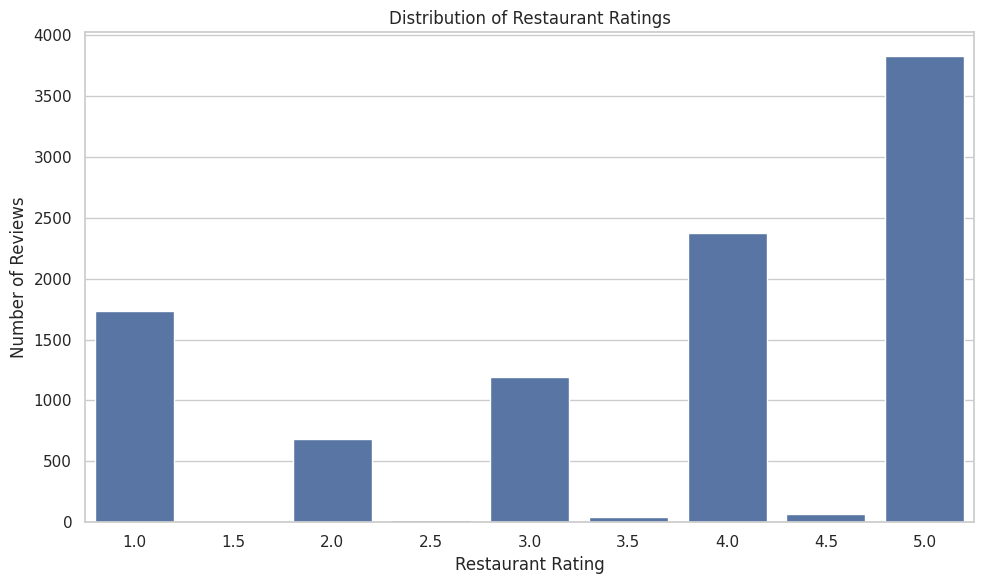

In [31]:
# STEP 18: RATING DISTRIBUTION ANALYSIS

# Remove records with missing ratings for this analysis
rating_data = zomato_df.dropna(subset=["Rating"]).copy()

# Calculate rating counts
rating_counts = rating_data["Rating"].value_counts().sort_index()

print("========== RATING DISTRIBUTION ==========")
print(rating_counts)

# Calculate average rating
average_rating = rating_data["Rating"].mean()

print("\nAverage Restaurant Rating:", round(average_rating, 2))
print("Total Rated Reviews:", len(rating_data))

# Create rating distribution chart
plt.figure(figsize=(10, 6))

sns.countplot(
    data=rating_data,
    x="Rating",
    order=sorted(rating_data["Rating"].unique())
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

========== TOP 10 MOST REVIEWED RESTAURANTS ==========


,Restaurant,Total Reviews
0,10 Downing Street,100
1,13 Dhaba,100
2,"3B's - Buddies, Bar & Barbecue",100
3,AB's - Absolute Barbecues,100
4,Absolute Sizzlers,100
5,B-Dubs,100
6,Asian Meal Box,100
7,Aromas@11SIX,100
8,Beyond Flavours,100
9,Behrouz Biryani,100


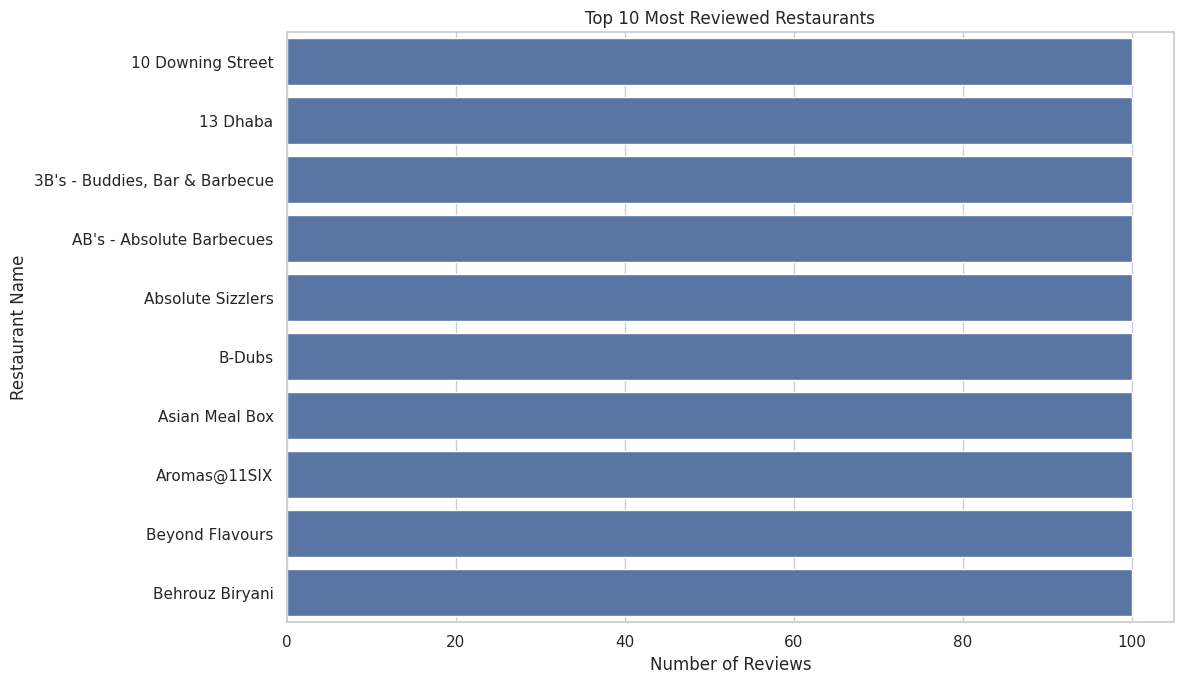

In [32]:
# STEP 19: TOP 10 MOST REVIEWED RESTAURANTS

# Count reviews for each restaurant
top_restaurants = (
    zomato_df.groupby("Restaurant")["Review"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print("========== TOP 10 MOST REVIEWED RESTAURANTS ==========")
display(top_restaurants.reset_index(name="Total Reviews"))

# Create visualization
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_restaurants.values,
    y=top_restaurants.index
)

plt.title("Top 10 Most Reviewed Restaurants")
plt.xlabel("Number of Reviews")
plt.ylabel("Restaurant Name")
plt.tight_layout()

# Save chart
plt.savefig("02_top_10_reviewed_restaurants.png", dpi=300)

plt.show()

========== TOP 10 MOST POPULAR CUISINES ==========


,Cuisines,Restaurant Count
0,North Indian,6000
1,Chinese,4100
2,Continental,2086
3,Biryani,1500
4,Asian,1400
5,Italian,1400
6,Desserts,1300
7,Fast Food,1278
8,South Indian,900
9,Kebab,600


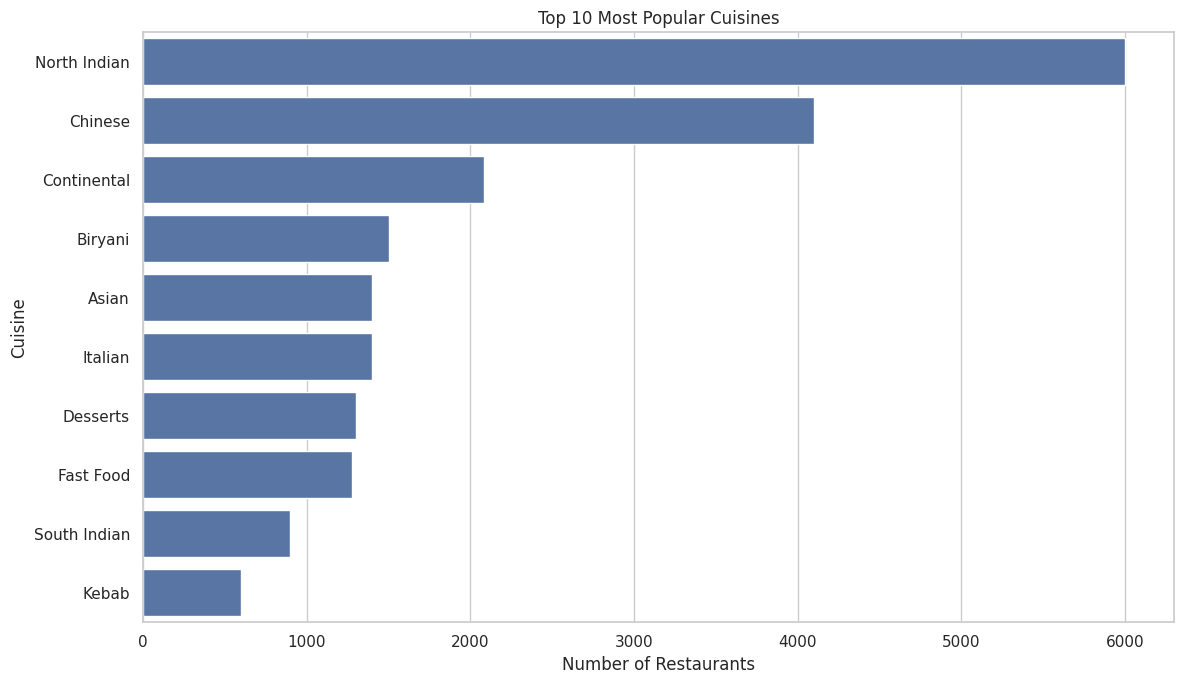

In [33]:
# STEP 20: TOP 10 MOST POPULAR CUISINES

# Extract cuisine information
cuisine_data = zomato_df["Cuisines"].dropna()

# Split multiple cuisines and create separate rows
cuisine_list = (
    cuisine_data.astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

# Remove empty and unknown values
cuisine_list = cuisine_list[
    (cuisine_list != "") &
    (cuisine_list.str.lower() != "unknown")
]

# Count the most popular cuisines
top_cuisines = cuisine_list.value_counts().head(10)

print("========== TOP 10 MOST POPULAR CUISINES ==========")
display(top_cuisines.reset_index(name="Restaurant Count"))

# Create visualization
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")
plt.tight_layout()

# Save chart
plt.savefig("03_top_10_popular_cuisines.png", dpi=300)

plt.show()

========== RESTAURANT COST ANALYSIS ==========
Total records with valid cost: 9964

Cost Statistics:


,Cost
count,9964.000000
mean,871.577680
std,503.437027
min,150.000000
25%,500.000000
50%,700.000000
75%,1200.000000
max,2800.000000



Average Restaurant Cost: 871.58
Minimum Cost: 150
Maximum Cost: 2800


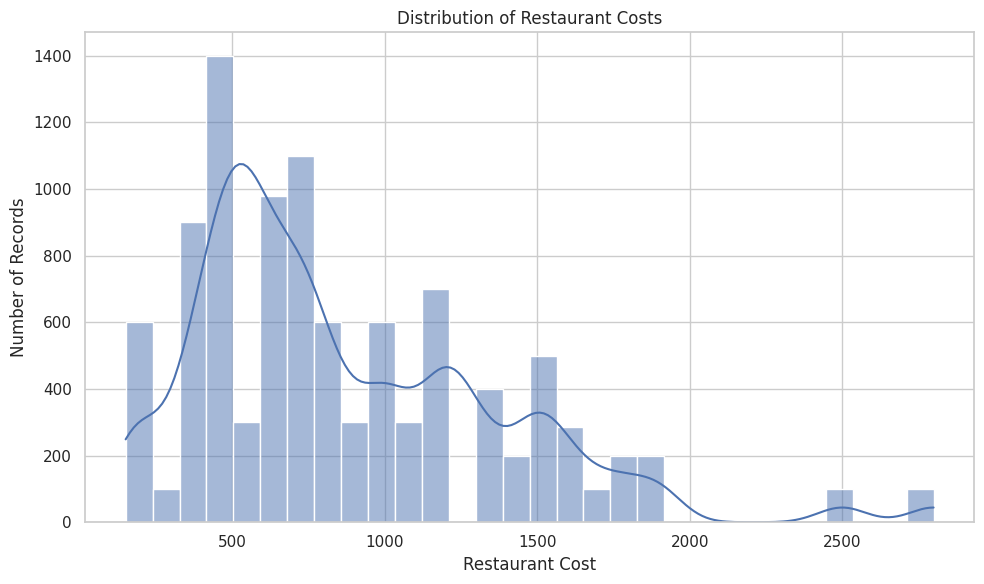

In [34]:
# STEP 21: RESTAURANT COST DISTRIBUTION

# Convert Cost into numeric values
zomato_df["Cost"] = pd.to_numeric(
    zomato_df["Cost"], errors="coerce"
)

# Remove missing and invalid costs for this analysis
cost_data = zomato_df.dropna(subset=["Cost"]).copy()

print("========== RESTAURANT COST ANALYSIS ==========")

print("Total records with valid cost:", len(cost_data))
print("\nCost Statistics:")
display(cost_data["Cost"].describe())

print("\nAverage Restaurant Cost:", round(cost_data["Cost"].mean(), 2))
print("Minimum Cost:", cost_data["Cost"].min())
print("Maximum Cost:", cost_data["Cost"].max())

# Create histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=cost_data,
    x="Cost",
    bins=30,
    kde=True
)

plt.title("Distribution of Restaurant Costs")
plt.xlabel("Restaurant Cost")
plt.ylabel("Number of Records")
plt.tight_layout()

# Save chart
plt.savefig("04_restaurant_cost_distribution.png", dpi=300)

plt.show()

========== TOP 10 HIGHEST-RATED CUISINES ==========


,Cuisines,mean,count
26,Mediterranean,4.552000,500
28,Modern Indian,4.410000,200
13,European,4.382500,400
4,BBQ,4.360000,200
16,Goan,4.220000,100
0,American,3.928943,577
3,Asian,3.917143,1400
19,Ice Cream,3.892500,200
39,Sushi,3.831250,400
11,Continental,3.816307,2085


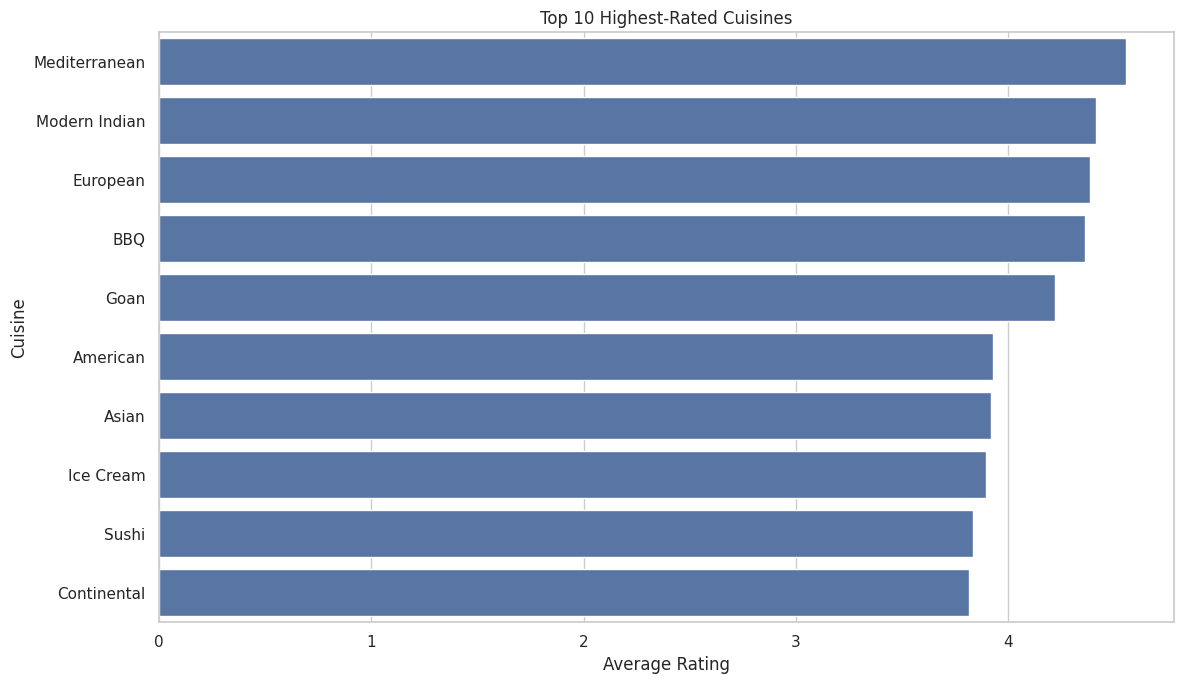

In [35]:
# STEP 22: AVERAGE RATING BY CUISINE

# Select records with valid ratings and cuisine information
cuisine_rating_data = zomato_df.dropna(
    subset=["Rating", "Cuisines"]
).copy()

# Split multiple cuisines
cuisine_rating_data["Cuisines"] = (
    cuisine_rating_data["Cuisines"].astype(str).str.split(",")
)

cuisine_rating_data = cuisine_rating_data.explode("Cuisines")

# Clean cuisine names
cuisine_rating_data["Cuisines"] = (
    cuisine_rating_data["Cuisines"].str.strip()
)

# Remove empty and unknown cuisines
cuisine_rating_data = cuisine_rating_data[
    (cuisine_rating_data["Cuisines"] != "") &
    (cuisine_rating_data["Cuisines"].str.lower() != "unknown")
]

# Calculate average rating
cuisine_avg_rating = (
    cuisine_rating_data.groupby("Cuisines")["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

# Keep cuisines with at least 20 reviews
cuisine_avg_rating = cuisine_avg_rating[
    cuisine_avg_rating["count"] >= 20
]

# Select top 10 highest-rated cuisines
top_rated_cuisines = cuisine_avg_rating.sort_values(
    by="mean", ascending=False
).head(10)

print("========== TOP 10 HIGHEST-RATED CUISINES ==========")

display(top_rated_cuisines)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_rated_cuisines,
    x="mean",
    y="Cuisines"
)

plt.title("Top 10 Highest-Rated Cuisines")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine")
plt.tight_layout()

# Save chart
plt.savefig("05_average_rating_by_cuisine.png", dpi=300)

plt.show()

========== COST VS RATING ANALYSIS ==========
Total valid records: 9961
Cost and Rating Correlation: 0.144


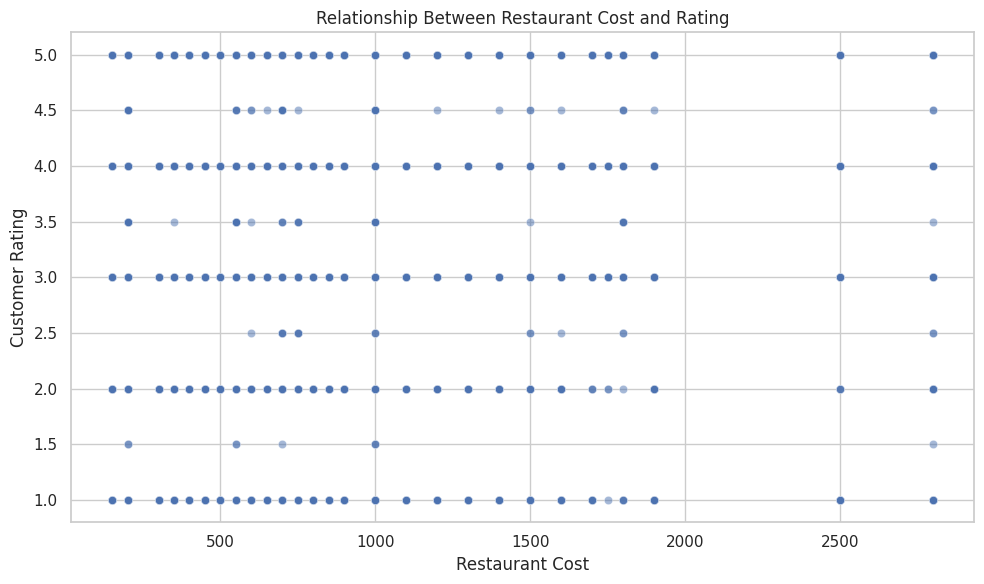

In [36]:
# STEP 23: RESTAURANT COST VS RATING

# Select records with valid cost and rating
cost_rating_data = zomato_df.dropna(
    subset=["Cost", "Rating"]
).copy()

print("========== COST VS RATING ANALYSIS ==========")

print("Total valid records:", len(cost_rating_data))

# Calculate correlation
correlation = cost_rating_data["Cost"].corr(
    cost_rating_data["Rating"]
)

print("Cost and Rating Correlation:", round(correlation, 3))

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cost_rating_data,
    x="Cost",
    y="Rating",
    alpha=0.5
)

plt.title("Relationship Between Restaurant Cost and Rating")
plt.xlabel("Restaurant Cost")
plt.ylabel("Customer Rating")
plt.tight_layout()

# Save chart
plt.savefig("06_cost_vs_rating.png", dpi=300)

plt.show()

========== REVIEW LENGTH ANALYSIS ==========

Review Length Statistics:


,Review_Length
count,9954.000000
mean,279.777979
std,338.615629
min,1.000000
25%,144.000000
50%,189.000000
75%,321.000000
max,5212.000000



Average Review Length: 279.78


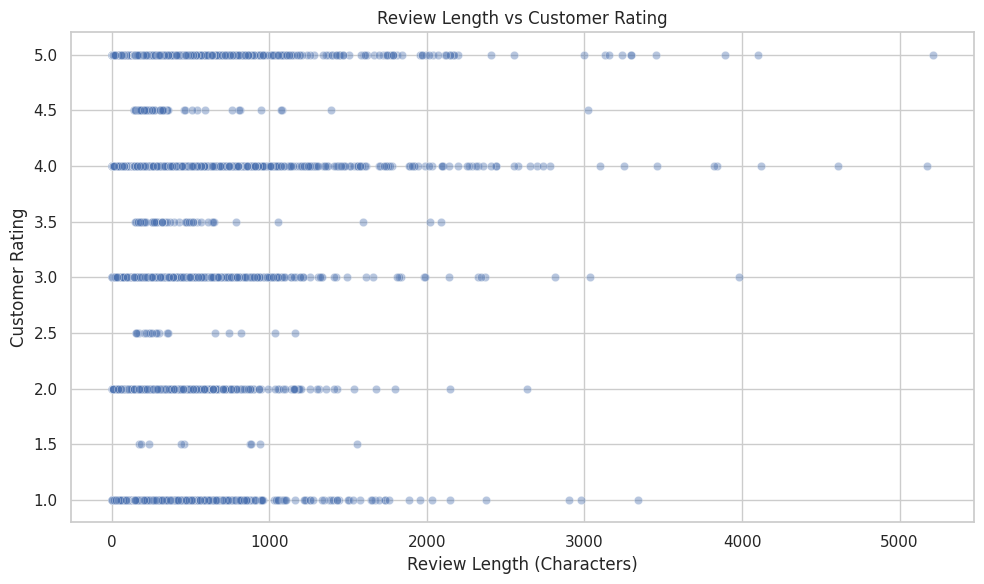

In [37]:
# STEP 24: REVIEW LENGTH ANALYSIS

# Select reviews with available text
review_length_data = zomato_df.dropna(
    subset=["Review", "Rating"]
).copy()

# Calculate review length
review_length_data["Review_Length"] = (
    review_length_data["Review"].astype(str).str.len()
)

# Display statistics
print("========== REVIEW LENGTH ANALYSIS ==========")

print("\nReview Length Statistics:")
display(review_length_data["Review_Length"].describe())

print("\nAverage Review Length:",
      round(review_length_data["Review_Length"].mean(), 2))

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=review_length_data,
    x="Review_Length",
    y="Rating",
    alpha=0.4
)

plt.title("Review Length vs Customer Rating")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Customer Rating")
plt.tight_layout()

# Save chart
plt.savefig("07_review_length_vs_rating.png", dpi=300)

plt.show()

========== RATING BY COST CATEGORY ==========


,Cost_Category,mean,count
0,Budget,3.356619,2999
1,Mid-Range,3.515218,3877
2,Expensive,3.946515,3085


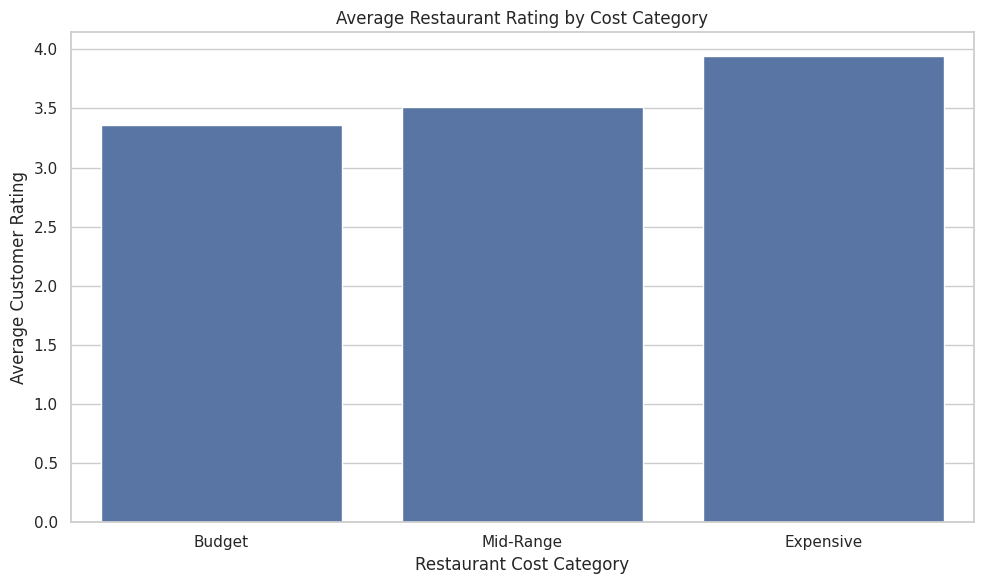

In [38]:
# STEP 25: RATING BY RESTAURANT COST CATEGORY

# Create a copy of valid records
cost_category_data = zomato_df.dropna(
    subset=["Cost", "Rating"]
).copy()

# Define restaurant cost categories
cost_category_data["Cost_Category"] = pd.cut(
    cost_category_data["Cost"],
    bins=[0, 500, 1000, float("inf")],
    labels=["Budget", "Mid-Range", "Expensive"],
    include_lowest=True
)

# Calculate average rating by cost category
category_ratings = (
    cost_category_data.groupby(
        "Cost_Category", observed=True
    )["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

print("========== RATING BY COST CATEGORY ==========")
display(category_ratings)

# Create visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_ratings,
    x="Cost_Category",
    y="mean"
)

plt.title("Average Restaurant Rating by Cost Category")
plt.xlabel("Restaurant Cost Category")
plt.ylabel("Average Customer Rating")
plt.tight_layout()

# Save chart
plt.savefig("08_rating_by_cost_category.png", dpi=300)

plt.show()

========== REVIEW RATINGS BY HOUR ==========


,Review_Hour,mean,count
0,0,3.469548,509
1,1,3.468051,313
2,2,3.577844,167
3,3,3.450980,102
4,4,3.772727,55
5,5,3.846154,39
6,6,3.693182,44
7,7,3.500000,78
8,8,3.421642,134
9,9,3.649123,171


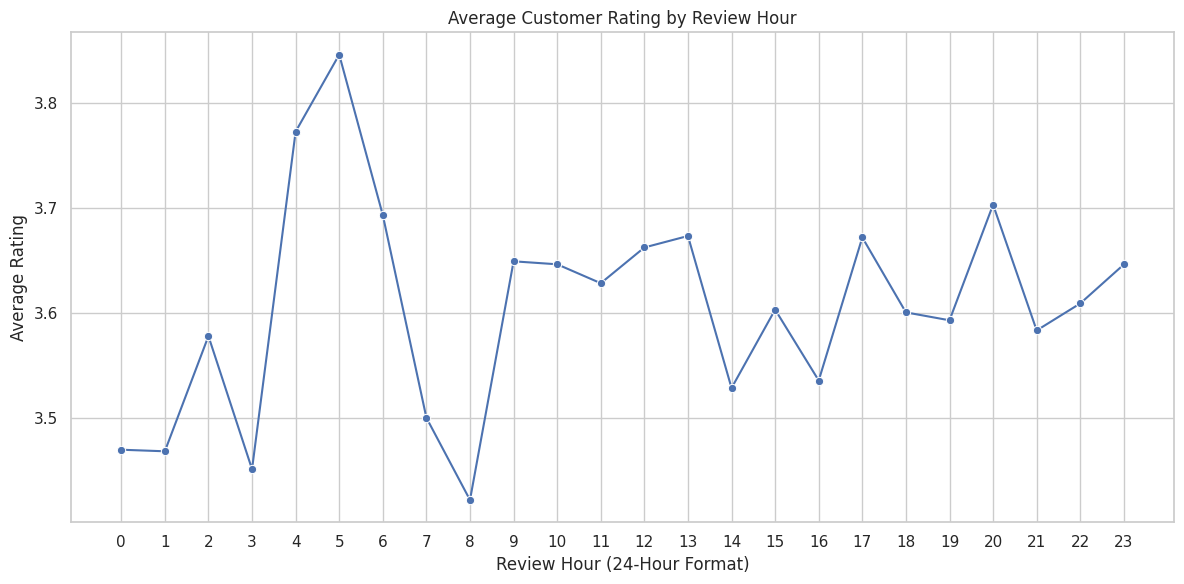

In [39]:
# STEP 26: REVIEW RATING DISTRIBUTION BY TIME

# Create a copy of the dataset
time_rating_data = zomato_df.dropna(
    subset=["Time", "Rating"]
).copy()

# Convert Time column to datetime
time_rating_data["Review_Time"] = pd.to_datetime(
    time_rating_data["Time"],
    errors="coerce"
)

# Remove invalid dates
time_rating_data = time_rating_data.dropna(
    subset=["Review_Time"]
)

# Extract hour from review time
time_rating_data["Review_Hour"] = (
    time_rating_data["Review_Time"].dt.hour
)

# Calculate average rating by hour
hourly_ratings = (
    time_rating_data.groupby("Review_Hour")["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

print("========== REVIEW RATINGS BY HOUR ==========")
display(hourly_ratings)

# Create chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_ratings,
    x="Review_Hour",
    y="mean",
    marker="o"
)

plt.title("Average Customer Rating by Review Hour")
plt.xlabel("Review Hour (24-Hour Format)")
plt.ylabel("Average Rating")
plt.xticks(range(0, 24))
plt.tight_layout()

# Save chart
plt.savefig("09_rating_by_review_hour.png", dpi=300)

plt.show()

========== REVIEW LENGTH DISTRIBUTION ==========


,Review_Length
count,9955.000000
mean,50.173079
std,60.783718
min,1.000000
25%,24.000000
50%,34.000000
75%,58.000000
max,964.000000



Average Review Word Count: 50.17


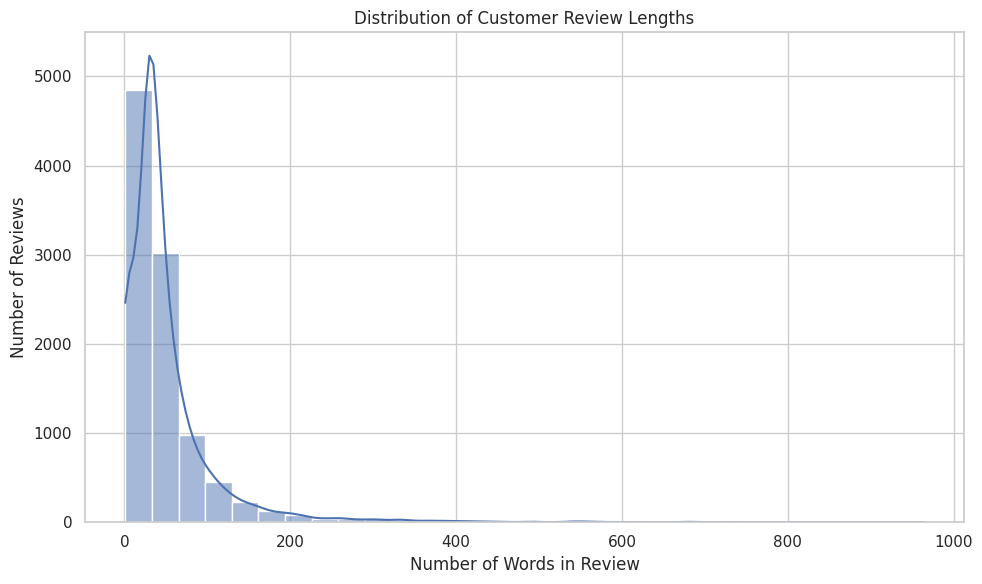

In [40]:
# STEP 27: REVIEW LENGTH DISTRIBUTION

# Select reviews with available text
review_length_distribution = zomato_df.dropna(
    subset=["Review"]
).copy()

# Calculate review length
review_length_distribution["Review_Length"] = (
    review_length_distribution["Review"]
    .astype(str)
    .str.split()
    .str.len()
)

# Display statistics
print("========== REVIEW LENGTH DISTRIBUTION ==========")

display(
    review_length_distribution["Review_Length"].describe()
)

print(
    "\nAverage Review Word Count:",
    round(review_length_distribution["Review_Length"].mean(), 2)
)

# Create histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=review_length_distribution,
    x="Review_Length",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Number of Words in Review")
plt.ylabel("Number of Reviews")
plt.tight_layout()

# Save chart
plt.savefig("10_review_length_distribution.png", dpi=300)

plt.show()

========== TOP 10 MOST ACTIVE REVIEWERS ==========


,Reviewer,Total Reviews
0,Ankita,13
1,Parijat Ray,13
2,Kiran,12
3,Jay Mehta,11
4,Vedant Killa,11
5,Sravani,10
6,Priyanka,10
7,Siva Kumar,10
8,Age Of Foodies (Suraj Karambe),10
9,Manojkumar D Nambisan,10


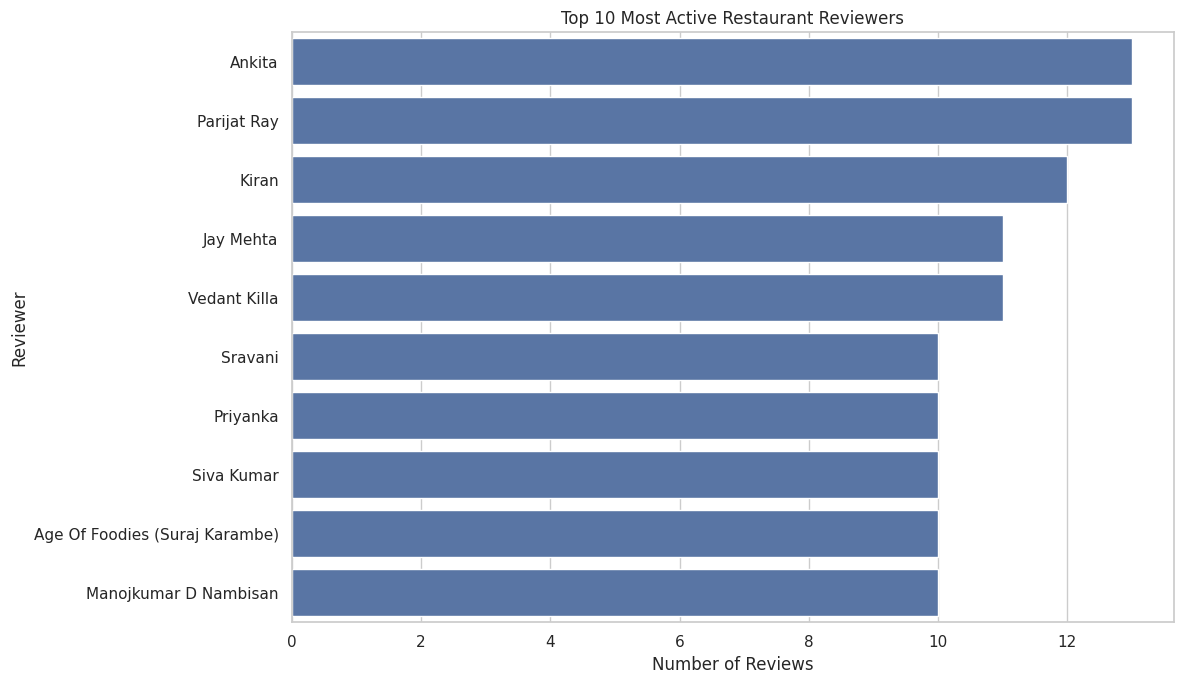

In [41]:
# STEP 28: TOP 10 MOST ACTIVE REVIEWERS

# Count reviews submitted by each reviewer
reviewer_counts = (
    zomato_df[zomato_df["Reviewer"].notna()]
    .groupby("Reviewer")["Review"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

print("========== TOP 10 MOST ACTIVE REVIEWERS ==========")

display(
    reviewer_counts.reset_index(name="Total Reviews")
)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=reviewer_counts.values,
    y=reviewer_counts.index
)

plt.title("Top 10 Most Active Restaurant Reviewers")
plt.xlabel("Number of Reviews")
plt.ylabel("Reviewer")
plt.tight_layout()

# Save chart
plt.savefig("11_top_10_active_reviewers.png", dpi=300)

plt.show()

========== TOP 10 RESTAURANT COLLECTIONS ==========


,Collections,Restaurant Count
0,Great Buffets,1100
1,Food Hygiene Rated Restaurants in Hyderabad,778
2,Live Sports Screenings,700
3,Hyderabad's Hottest,700
4,Corporate Favorites,600
5,Gold Curated,500
6,Top-Rated,500
7,Trending This Week,500
8,Best Bars & Pubs,400
9,Sunday Brunches,400


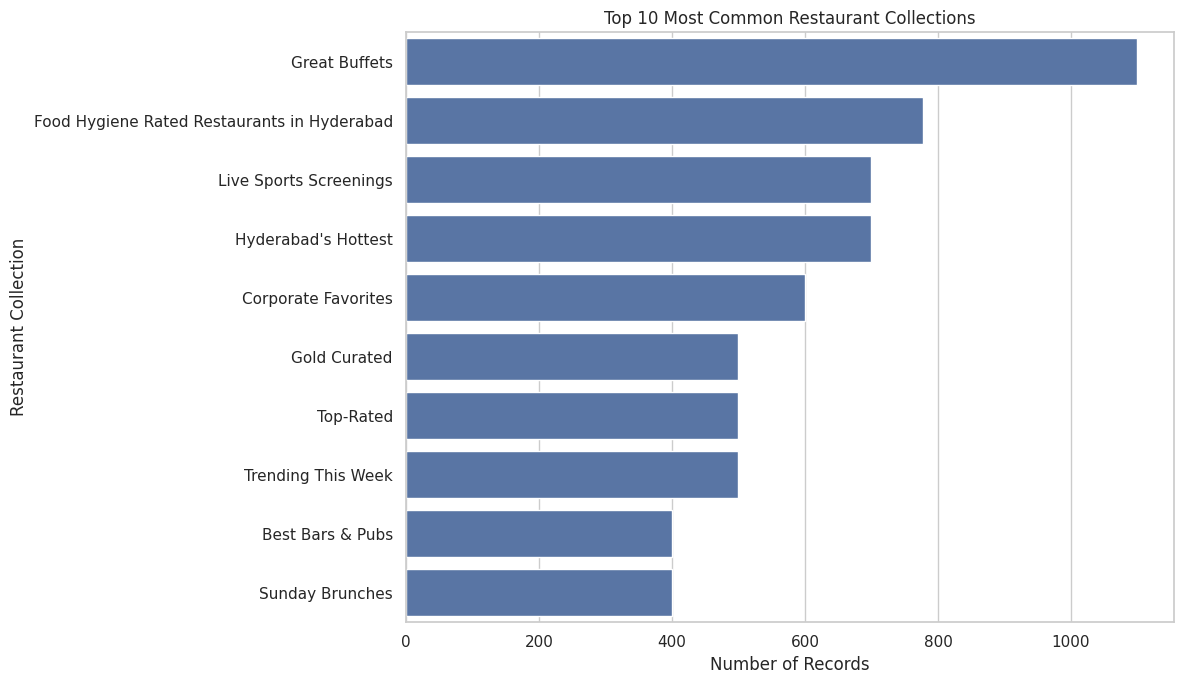

In [42]:
# STEP 29: RESTAURANT COLLECTIONS ANALYSIS

# Select available collections
collection_data = zomato_df["Collections"].dropna()

# Split multiple collections into separate values
collection_list = (
    collection_data.astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

# Remove empty and unknown values
collection_list = collection_list[
    (collection_list != "") &
    (collection_list.str.lower() != "unknown")
]

# Find the top 10 collections
top_collections = collection_list.value_counts().head(10)

print("========== TOP 10 RESTAURANT COLLECTIONS ==========")

display(
    top_collections.reset_index(name="Restaurant Count")
)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_collections.values,
    y=top_collections.index
)

plt.title("Top 10 Most Common Restaurant Collections")
plt.xlabel("Number of Records")
plt.ylabel("Restaurant Collection")
plt.tight_layout()

# Save chart
plt.savefig("12_top_10_restaurant_collections.png", dpi=300)

plt.show()

========== TOP 10 MOST COMMON RESTAURANT TIMINGS ==========


,Timings,Restaurant Count
0,11 AM to 11 PM,500
1,12 Noon to 12 Midnight,486
2,12 Noon to 11 PM,400
3,11:30 AM to 1 AM,300
4,12 Noon to 10:30 PM,300
5,"12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",200
6,12noon to 12midnight (Mon-Sun),200
7,12noon to 11pm (Mon-Sun),200
8,10 AM to 10 PM,200
9,"12 Noon to 12 Midnight (Mon-Thu, Sun), 12 Noon...",200


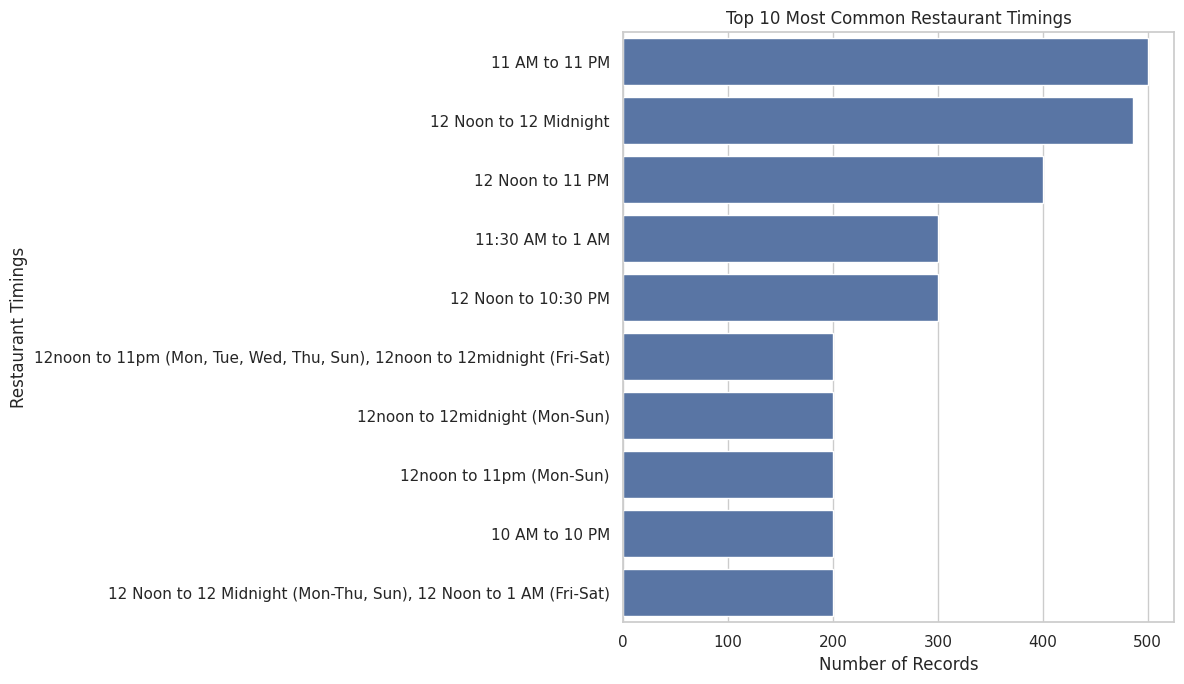

In [43]:
# STEP 30: RESTAURANT TIMINGS ANALYSIS

# Select available restaurant timings
timing_data = zomato_df["Timings"].dropna().astype(str)

# Count the most common timings
top_timings = timing_data.value_counts().head(10)

print("========== TOP 10 MOST COMMON RESTAURANT TIMINGS ==========")

display(
    top_timings.reset_index(name="Restaurant Count")
)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_timings.values,
    y=top_timings.index
)

plt.title("Top 10 Most Common Restaurant Timings")
plt.xlabel("Number of Records")
plt.ylabel("Restaurant Timings")
plt.tight_layout()

# Save chart
plt.savefig("13_top_10_restaurant_timings.png", dpi=300)

plt.show()

========== RATINGS BY PICTURE CATEGORY ==========


,Picture_Category,mean,count
0,With Pictures,3.863338,1983
1,Without Pictures,3.535849,7978


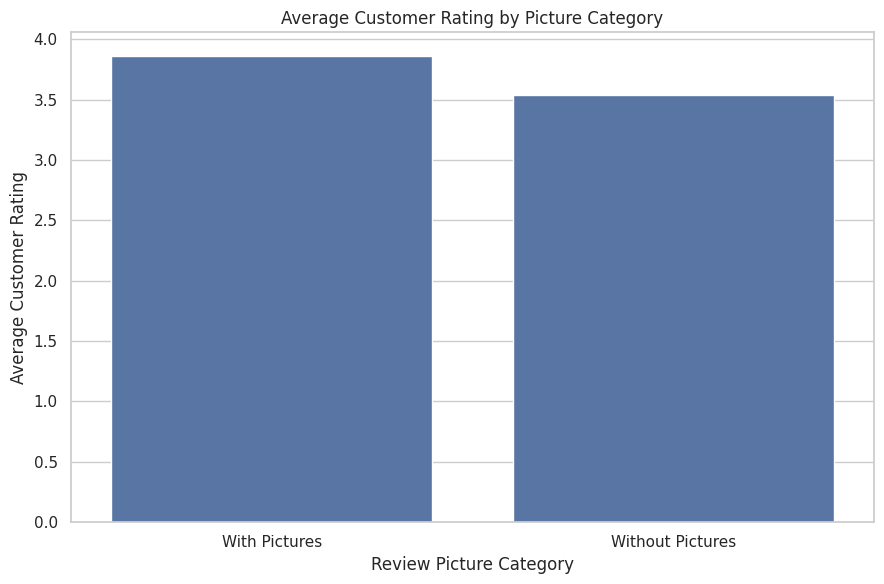

In [44]:
# STEP 31: CUSTOMER RATINGS BY PICTURES

# Create a copy of valid records
picture_rating_data = zomato_df.dropna(
    subset=["Rating", "Pictures"]
).copy()

# Convert Pictures into numeric values
picture_rating_data["Pictures"] = pd.to_numeric(
    picture_rating_data["Pictures"],
    errors="coerce"
)

picture_rating_data = picture_rating_data.dropna(
    subset=["Pictures"]
)

# Create picture categories
picture_rating_data["Picture_Category"] = np.where(
    picture_rating_data["Pictures"] > 0,
    "With Pictures",
    "Without Pictures"
)

# Calculate average rating
picture_rating_summary = (
    picture_rating_data.groupby("Picture_Category")["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

print("========== RATINGS BY PICTURE CATEGORY ==========")
display(picture_rating_summary)

# Create chart
plt.figure(figsize=(9, 6))

sns.barplot(
    data=picture_rating_summary,
    x="Picture_Category",
    y="mean"
)

plt.title("Average Customer Rating by Picture Category")
plt.xlabel("Review Picture Category")
plt.ylabel("Average Customer Rating")
plt.tight_layout()

# Save chart
plt.savefig("14_ratings_by_picture_category.png", dpi=300)

plt.show()

========== CORRELATION MATRIX ==========


,Rating,Cost,Pictures,Review_Length
Rating,1.00,0.14,0.08,-0.04
Cost,0.14,1.00,0.11,0.20
Pictures,0.08,0.11,1.00,0.46
Review_Length,-0.04,0.20,0.46,1.00


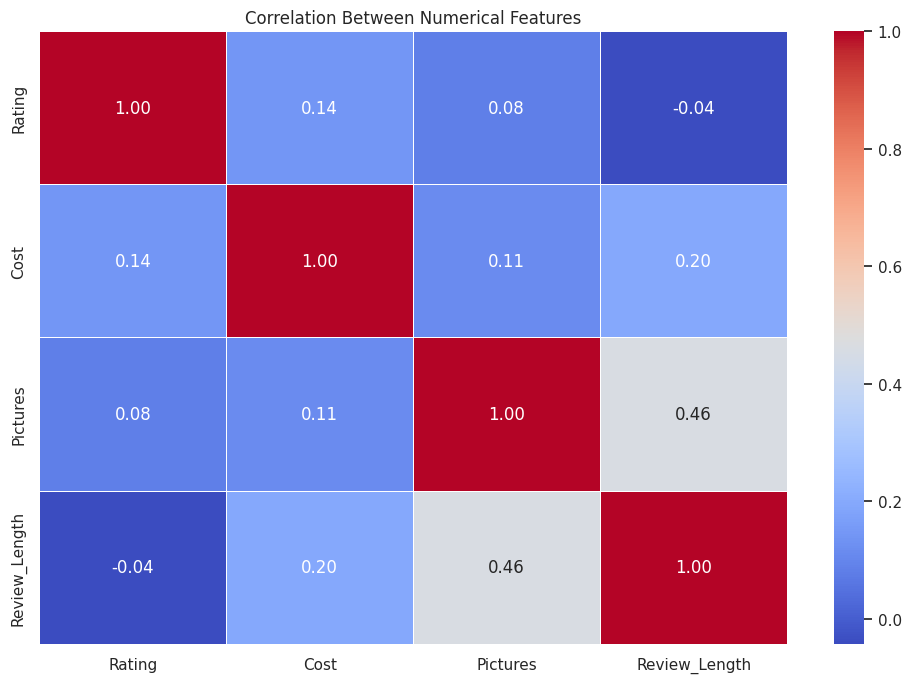

In [45]:
# STEP 32: CORRELATION ANALYSIS

# Create a copy of the dataset
correlation_data = zomato_df.copy()

# Calculate review length
correlation_data["Review_Length"] = (
    correlation_data["Review"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Select numerical columns
numerical_data = correlation_data[
    ["Rating", "Cost", "Pictures", "Review_Length"]
].apply(pd.to_numeric, errors="coerce")

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

print("========== CORRELATION MATRIX ==========")
display(correlation_matrix.round(2))

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()

# Save chart
plt.savefig("15_numerical_features_correlation.png", dpi=300)

plt.show()

========== TOP 20 MOST FREQUENT WORDS ==========


,Word,Frequency
5,good,7230
4,food,6641
11,place,5734
14,service,3246
3,chicken,3105
16,taste,2283
10,ordered,2178
0,ambience,2126
6,great,1978
12,really,1674


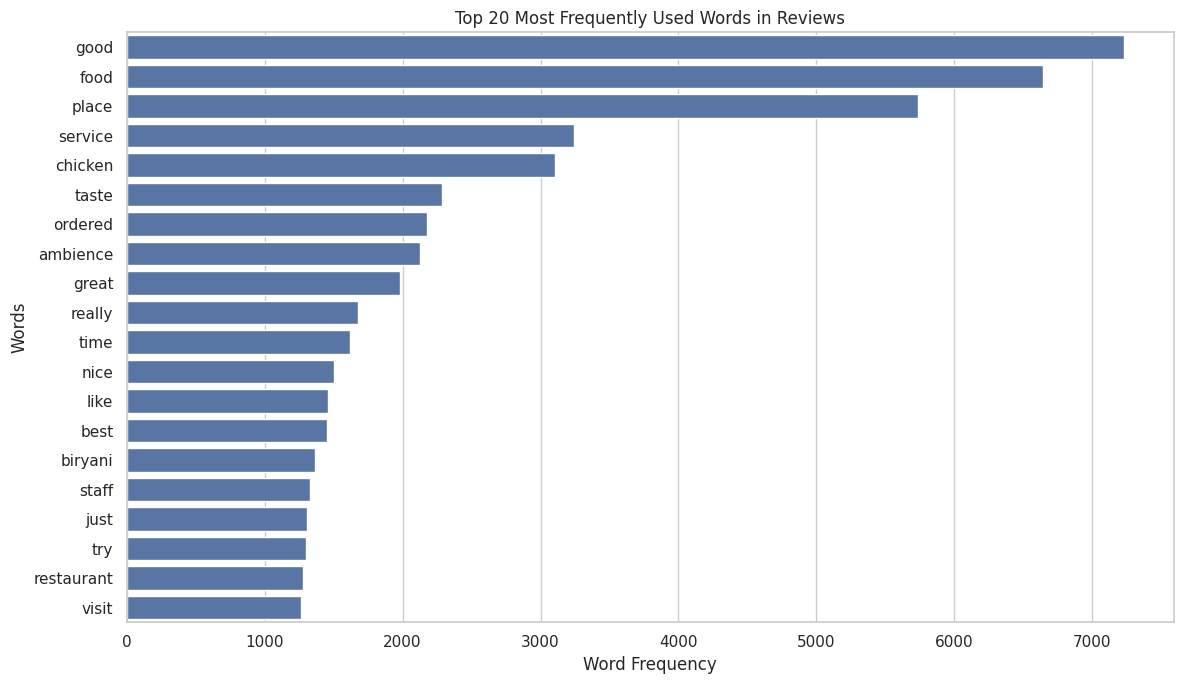

In [46]:
# STEP 33: MOST FREQUENT WORDS IN CUSTOMER REVIEWS

from sklearn.feature_extraction.text import CountVectorizer

# Select valid review text
review_text_data = (
    zomato_df["Review"]
    .dropna()
    .astype(str)
)

# Convert text into word counts
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
)

word_matrix = vectorizer.fit_transform(review_text_data)

# Calculate word frequencies
word_frequencies = np.asarray(
    word_matrix.sum(axis=0)
).ravel()

word_frequency_df = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "Frequency": word_frequencies
})

word_frequency_df = word_frequency_df.sort_values(
    by="Frequency",
    ascending=False
)

print("========== TOP 20 MOST FREQUENT WORDS ==========")
display(word_frequency_df)

# Create chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_frequency_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequently Used Words in Reviews")
plt.xlabel("Word Frequency")
plt.ylabel("Words")
plt.tight_layout()

# Save chart
plt.savefig("16_most_frequent_review_words.png", dpi=300)

plt.show()

========== CUSTOMER SENTIMENT ANALYSIS ==========


,Sentiment,Review Count
0,Positive,6651
1,Neutral,2277
2,Negative,1027


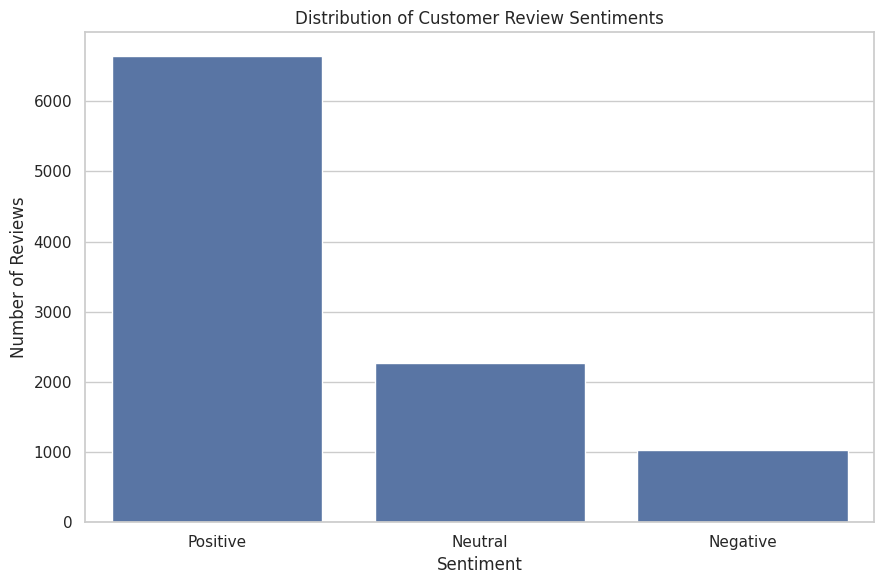

In [47]:
# STEP 34: POSITIVE AND NEGATIVE REVIEW ANALYSIS

# Create a copy of the dataset
sentiment_data = zomato_df.dropna(
    subset=["Review"]
).copy()

# Define positive and negative words
positive_words = [
    "good", "great", "excellent", "amazing",
    "delicious", "best", "awesome", "love",
    "friendly", "tasty", "perfect", "wonderful"
]

negative_words = [
    "bad", "worst", "poor", "terrible",
    "awful", "disappointing", "rude", "slow",
    "dirty", "expensive", "unhappy", "horrible"
]

# Calculate sentiment scores
def calculate_sentiment(review):
    review = str(review).lower()

    positive_count = sum(
        review.count(word) for word in positive_words
    )

    negative_count = sum(
        review.count(word) for word in negative_words
    )

    if positive_count > negative_count:
        return "Positive"
    elif negative_count > positive_count:
        return "Negative"
    else:
        return "Neutral"

# Apply sentiment analysis
sentiment_data["Sentiment"] = (
    sentiment_data["Review"].apply(calculate_sentiment)
)

# Count sentiment categories
sentiment_counts = sentiment_data["Sentiment"].value_counts()

print("========== CUSTOMER SENTIMENT ANALYSIS ==========")
display(sentiment_counts.reset_index(name="Review Count"))

# Create chart
plt.figure(figsize=(9, 6))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Distribution of Customer Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

# Save chart
plt.savefig("17_customer_sentiment_analysis.png", dpi=300)

plt.show()

========== SENTIMENT VS RESTAURANT RATING ==========


,Sentiment,mean,count
0,Negative,1.495618,1027
1,Neutral,2.837286,2277
2,Positive,4.186541,6650


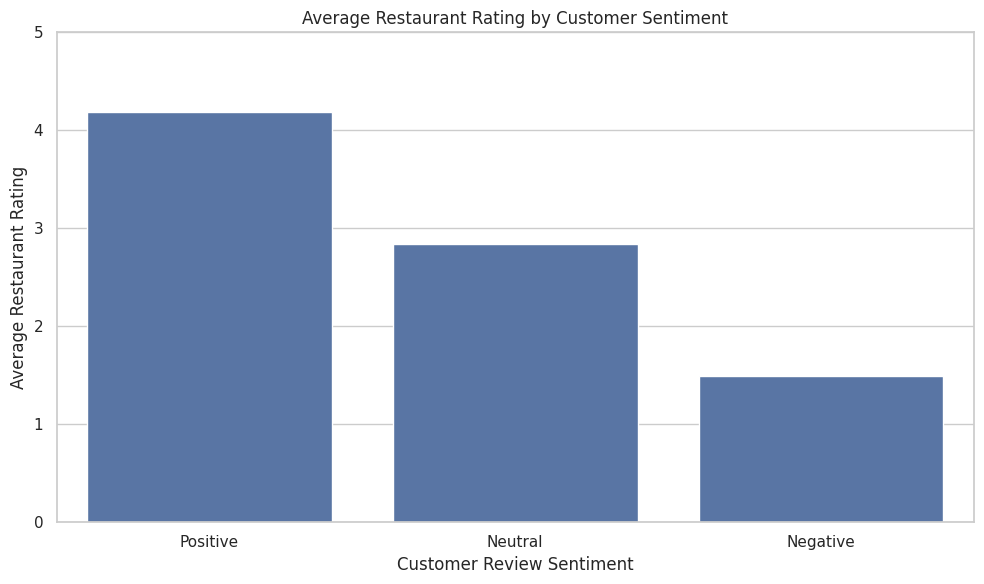

In [48]:
# STEP 35: CUSTOMER SENTIMENT VS RESTAURANT RATING

# Create a dataset with valid reviews and ratings
final_analysis = zomato_df.dropna(
    subset=["Review", "Rating"]
).copy()

# Use the sentiment function created in Step 34
final_analysis["Sentiment"] = (
    final_analysis["Review"].apply(calculate_sentiment)
)

# Calculate average rating for each sentiment
sentiment_rating = (
    final_analysis.groupby("Sentiment")["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

print("========== SENTIMENT VS RESTAURANT RATING ==========")
display(sentiment_rating)

# Create final chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=sentiment_rating,
    x="Sentiment",
    y="mean",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Average Restaurant Rating by Customer Sentiment")
plt.xlabel("Customer Review Sentiment")
plt.ylabel("Average Restaurant Rating")
plt.ylim(0, 5)
plt.tight_layout()

# Save final chart
plt.savefig("18_final_sentiment_vs_rating.png", dpi=300)

plt.show()

========== SENTIMENT VS RESTAURANT RATING ==========


,Sentiment,mean,count
0,Negative,1.495618,1027
1,Neutral,2.837286,2277
2,Positive,4.186541,6650


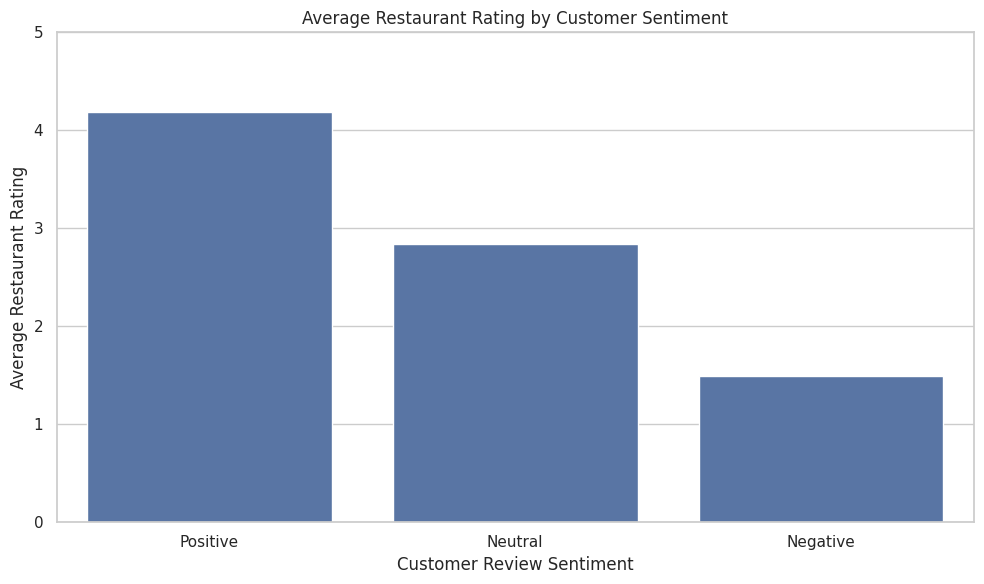

In [49]:
# STEP 35: CUSTOMER SENTIMENT VS RESTAURANT RATING

# Create a dataset with valid reviews and ratings
final_analysis = zomato_df.dropna(
    subset=["Review", "Rating"]
).copy()

# Use the sentiment function created in Step 34
final_analysis["Sentiment"] = (
    final_analysis["Review"].apply(calculate_sentiment)
)

# Calculate average rating for each sentiment
sentiment_rating = (
    final_analysis.groupby("Sentiment")["Rating"]
    .agg(["mean", "count"])
    .reset_index()
)

print("========== SENTIMENT VS RESTAURANT RATING ==========")
display(sentiment_rating)

# Create final chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=sentiment_rating,
    x="Sentiment",
    y="mean",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Average Restaurant Rating by Customer Sentiment")
plt.xlabel("Customer Review Sentiment")
plt.ylabel("Average Restaurant Rating")
plt.ylim(0, 5)
plt.tight_layout()

# Save final chart
plt.savefig("18_final_sentiment_vs_rating.png", dpi=300)

plt.show()

In [50]:
# STEP 36: HYPOTHESIS TEST 1
# Restaurant Cost vs Customer Rating

from scipy.stats import spearmanr

# Select valid cost and rating records
hypothesis_data = zomato_df.dropna(
    subset=["Cost", "Rating"]
).copy()

# Perform Spearman correlation test
correlation, p_value = spearmanr(
    hypothesis_data["Cost"],
    hypothesis_data["Rating"]
)

print("========== HYPOTHESIS TEST 1 ==========")
print("Restaurant Cost vs Customer Rating")

print("\nNull Hypothesis (H0):")
print("There is no significant relationship between cost and rating.")

print("\nAlternative Hypothesis (H1):")
print("There is a significant relationship between cost and rating.")

print("\nSpearman Correlation:", round(correlation, 4))
print("P-value:", p_value)

# Interpret the result
significance_level = 0.05

if p_value < significance_level:
    print("\nResult: Reject the Null Hypothesis (H0).")
    print("There is a statistically significant relationship.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0).")
    print("There is insufficient evidence of a significant relationship.")

========== HYPOTHESIS TEST 1 ==========
Restaurant Cost vs Customer Rating

Null Hypothesis (H0):
There is no significant relationship between cost and rating.

Alternative Hypothesis (H1):
There is a significant relationship between cost and rating.

Spearman Correlation: 0.1368
P-value: 7.982550877797052e-43

Result: Reject the Null Hypothesis (H0).
There is a statistically significant relationship.


In [51]:
# STEP 37: HYPOTHESIS TEST 2
# Pictures vs Customer Ratings

from scipy.stats import mannwhitneyu

# Select valid records
picture_test_data = zomato_df.dropna(
    subset=["Rating", "Pictures"]
).copy()

# Separate ratings into two groups
ratings_with_pictures = picture_test_data.loc[
    picture_test_data["Pictures"] > 0, "Rating"
]

ratings_without_pictures = picture_test_data.loc[
    picture_test_data["Pictures"] == 0, "Rating"
]

print("========== HYPOTHESIS TEST 2 ==========")
print("Pictures vs Customer Ratings")

print("\nReviews with pictures:", len(ratings_with_pictures))
print("Reviews without pictures:", len(ratings_without_pictures))

# Perform Mann-Whitney U test
if len(ratings_with_pictures) > 0 and len(ratings_without_pictures) > 0:

    statistic, p_value = mannwhitneyu(
        ratings_with_pictures,
        ratings_without_pictures,
        alternative="two-sided"
    )

    print("\nNull Hypothesis (H0):")
    print("There is no significant difference between the two groups.")

    print("\nAlternative Hypothesis (H1):")
    print("There is a significant difference between the two groups.")

    print("\nAverage rating with pictures:",
          round(ratings_with_pictures.mean(), 2))

    print("Average rating without pictures:",
          round(ratings_without_pictures.mean(), 2))

    print("\nMann-Whitney U Statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("\nResult: Reject the Null Hypothesis (H0).")
        print("A statistically significant difference was found.")
    else:
        print("\nResult: Fail to Reject the Null Hypothesis (H0).")
        print("There is insufficient evidence of a significant difference.")

else:
    print("\nThe test cannot be performed because one group is empty.")

========== HYPOTHESIS TEST 2 ==========
Pictures vs Customer Ratings

Reviews with pictures: 1983
Reviews without pictures: 7978

Null Hypothesis (H0):
There is no significant difference between the two groups.

Alternative Hypothesis (H1):
There is a significant difference between the two groups.

Average rating with pictures: 3.86
Average rating without pictures: 3.54

Mann-Whitney U Statistic: 8241655.5
P-value: 0.0025966066998002156

Result: Reject the Null Hypothesis (H0).
A statistically significant difference was found.


In [52]:
# STEP 38: HYPOTHESIS TEST 3
# Review Length vs Customer Rating

from scipy.stats import spearmanr

# Select valid reviews and ratings
review_test_data = zomato_df.dropna(
    subset=["Review", "Rating"]
).copy()

# Calculate review length in words
review_test_data["Review_Length"] = (
    review_test_data["Review"]
    .astype(str)
    .str.split()
    .str.len()
)

# Perform Spearman correlation test
correlation, p_value = spearmanr(
    review_test_data["Review_Length"],
    review_test_data["Rating"]
)

print("========== HYPOTHESIS TEST 3 ==========")
print("Review Length vs Customer Rating")

print("\nNull Hypothesis (H0):")
print("There is no significant relationship between review length and rating.")

print("\nAlternative Hypothesis (H1):")
print("There is a significant relationship between review length and rating.")

print("\nSpearman Correlation:", round(correlation, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("\nResult: Reject the Null Hypothesis (H0).")
    print("A statistically significant relationship was found.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0).")
    print("There is insufficient evidence of a significant relationship.")

========== HYPOTHESIS TEST 3 ==========
Review Length vs Customer Rating

Null Hypothesis (H0):
There is no significant relationship between review length and rating.

Alternative Hypothesis (H1):
There is a significant relationship between review length and rating.

Spearman Correlation: -0.1418
P-value: 7.347135018535012e-46

Result: Reject the Null Hypothesis (H0).
A statistically significant relationship was found.


In [53]:
# STEP 39: TEXT PREPROCESSING

import re

# Create a copy of the merged dataset
modeling_df = zomato_df.copy()

# Remove records without valid ratings or review text
modeling_df = modeling_df.dropna(
    subset=["Rating", "Review"]
).copy()

# Remove placeholder reviews
modeling_df = modeling_df[
    modeling_df["Review"].astype(str).str.lower() != "unknown"
].copy()

# Clean review text
def clean_review_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply text cleaning
modeling_df["Cleaned_Review"] = (
    modeling_df["Review"].apply(clean_review_text)
)

# Remove empty cleaned reviews
modeling_df = modeling_df[
    modeling_df["Cleaned_Review"].str.len() > 0
].copy()

print("========== TEXT PREPROCESSING RESULTS ==========")

print("Original merged records:", len(zomato_df))
print("Records after preprocessing:", len(modeling_df))

print("\nOriginal Reviews:")
display(modeling_df[["Review"]].head(10))

print("\nCleaned Reviews:")
display(modeling_df[["Cleaned_Review"]].head(10))

print("\nMissing values in cleaned reviews:")
print(modeling_df["Cleaned_Review"].isnull().sum())

print("\nText preprocessing completed successfully!")

========== TEXT PREPROCESSING RESULTS ==========
Original merged records: 9964
Records after preprocessing: 9938

Original Reviews:


,Review
0,"The ambience was good, food was quite good . h..."
1,Ambience is too good for a pleasant evening. S...
2,A must try.. great food great ambience. Thnx f...
3,Soumen das and Arun was a great guy. Only beca...
4,Food is good.we ordered Kodi drumsticks and ba...
5,"Ambiance is good, service is good, food is aPr..."
6,"Its a very nice place, ambience is different, ..."
7,Well after reading so many reviews finally vis...
8,"Excellent food , specially if you like spicy f..."
9,Came for the birthday treat of a close friend....



Cleaned Reviews:


,Cleaned_Review
0,the ambience was good food was quite good had ...
1,ambience is too good for a pleasant evening se...
2,a must try great food great ambience thnx for ...
3,soumen das and arun was a great guy only becau...
4,food is good we ordered kodi drumsticks and ba...
5,ambiance is good service is good food is aprad...
6,its a very nice place ambience is different al...
7,well after reading so many reviews finally vis...
8,excellent food specially if you like spicy foo...
9,came for the birthday treat of a close friend ...



Missing values in cleaned reviews:
0

Text preprocessing completed successfully!


In [54]:
# STEP 40: FEATURE ENGINEERING

# Create a copy of the preprocessed dataset
feature_df = modeling_df.copy()

# 1. Calculate review word count
feature_df["Review_Word_Count"] = (
    feature_df["Cleaned_Review"].str.split().str.len()
)

# 2. Calculate review character count
feature_df["Review_Character_Count"] = (
    feature_df["Cleaned_Review"].str.len()
)

# 3. Calculate number of cuisines
feature_df["Cuisine_Count"] = (
    feature_df["Cuisines"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: len([
            item for item in x.split(",")
            if item.strip() and item.strip().lower() != "unknown"
        ])
    )
)

# 4. Calculate number of collections
feature_df["Collection_Count"] = (
    feature_df["Collections"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: len([
            item for item in x.split(",")
            if item.strip() and item.strip().lower() != "unknown"
        ])
    )
)

# 5. Convert restaurant cost into numeric format
feature_df["Cost"] = pd.to_numeric(
    feature_df["Cost"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# 6. Convert picture count into numeric format
feature_df["Pictures"] = pd.to_numeric(
    feature_df["Pictures"],
    errors="coerce"
)

# Display engineered features
engineered_columns = [
    "Rating",
    "Review_Word_Count",
    "Review_Character_Count",
    "Cuisine_Count",
    "Collection_Count",
    "Cost",
    "Pictures"
]

print("========== ENGINEERED FEATURES ==========")

display(feature_df[engineered_columns].head(10))

print("\nFeature Dataset Shape:", feature_df.shape)

print("\nNew Feature Statistics:")
display(feature_df[engineered_columns].describe())

print("\nFeature engineering completed successfully!")

========== ENGINEERED FEATURES ==========


,Rating,Review_Word_Count,Review_Character_Count,Cuisine_Count,Collection_Count,Cost,Pictures
0,5.0,38,212,6,6,800,0
1,5.0,26,138,6,6,800,0
2,5.0,30,174,6,6,800,0
3,5.0,28,144,6,6,800,0
4,5.0,28,154,6,6,800,0
5,5.0,28,155,6,6,800,0
6,5.0,31,163,6,6,800,0
7,4.0,48,276,6,6,800,0
8,5.0,30,186,6,6,800,0
9,5.0,53,288,6,6,800,0



Feature Dataset Shape: (9938, 19)

New Feature Statistics:


,Rating,Review_Word_Count,Review_Character_Count,Cuisine_Count,Collection_Count,Cost,Pictures
count,9938.000000,9938.000000,9938.000000,9938.000000,9938.000000,9938.000000,9938.000000
mean,3.599718,50.104146,269.771483,3.011069,1.052727,872.283156,0.753170
std,1.483588,60.575906,326.295600,1.203413,1.469161,503.720973,2.577715
min,1.000000,1.000000,1.000000,1.000000,0.000000,150.000000,0.000000
25%,3.000000,25.000000,139.000000,2.000000,0.000000,500.000000,0.000000
50%,4.000000,34.000000,183.000000,3.000000,0.000000,700.000000,0.000000
75%,5.000000,58.000000,310.000000,4.000000,2.000000,1200.000000,0.000000
max,5.000000,969.000000,5099.000000,6.000000,7.000000,2800.000000,64.000000



Feature engineering completed successfully!


In [55]:
# STEP 41: FEATURE AND TARGET SELECTION

# Select input features
feature_columns = [
    "Cleaned_Review",
    "Cost",
    "Pictures",
    "Review_Word_Count",
    "Review_Character_Count",
    "Cuisine_Count",
    "Collection_Count"
]

# Create feature dataset
X = feature_df[feature_columns].copy()

# Select target variable
y = feature_df["Rating"].copy()

# Remove rows with missing target values
valid_target = y.notna()

X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("========== FEATURE AND TARGET SELECTION ==========")

print("\nSelected Features:")
print(feature_columns)

print("\nFeature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nTarget Rating Distribution:")
display(y.value_counts().sort_index())

print("\nFirst 5 Feature Records:")
display(X.head())

print("\nFirst 5 Target Values:")
display(y.head())

print("\nFeature and target selection completed!")

========== FEATURE AND TARGET SELECTION ==========

Selected Features:
['Cleaned_Review', 'Cost', 'Pictures', 'Review_Word_Count', 'Review_Character_Count', 'Cuisine_Count', 'Collection_Count']

Feature Dataset Shape: (9938, 7)
Target Dataset Shape: (9938,)

Target Rating Distribution:


,count
Rating,
1.0,1733
1.5,9
2.0,683
2.5,19
3.0,1190
3.5,47
4.0,2371
4.5,69
5.0,3817



First 5 Feature Records:


,Cleaned_Review,Cost,Pictures,Review_Word_Count,Review_Character_Count,Cuisine_Count,Collection_Count
0,the ambience was good food was quite good had ...,800,0,38,212,6,6
1,ambience is too good for a pleasant evening se...,800,0,26,138,6,6
2,a must try great food great ambience thnx for ...,800,0,30,174,6,6
3,soumen das and arun was a great guy only becau...,800,0,28,144,6,6
4,food is good we ordered kodi drumsticks and ba...,800,0,28,154,6,6



First 5 Target Values:


,Rating
0,5.0
1,5.0
2,5.0
3,5.0
4,5.0



Feature and target selection completed!


In [56]:
# STEP 42: TRAIN-TEST SPLIT

from sklearn.model_selection import GroupShuffleSplit

# Identify restaurant groups
groups = feature_df.loc[X.index, "Restaurant_Key"]

# Create group-based train-test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

# Check restaurant overlap
train_restaurants = set(groups.iloc[train_indices])
test_restaurants = set(groups.iloc[test_indices])

print("========== TRAIN-TEST SPLIT REPORT ==========")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Records:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Records:",
      round(len(X_test) / len(X) * 100, 2), "%")

print("\nRestaurants in Training:", len(train_restaurants))
print("Restaurants in Testing:", len(test_restaurants))

print("Common Restaurants:",
      len(train_restaurants.intersection(test_restaurants)))

print("\nTrain-test splitting completed successfully!")

========== TRAIN-TEST SPLIT REPORT ==========

Training Features: (7944, 7)
Testing Features: (1994, 7)

Training Target: (7944,)
Testing Target: (1994,)

Training Records: 79.94 %
Testing Records: 20.06 %

Restaurants in Training: 80
Restaurants in Testing: 20
Common Restaurants: 0

Train-test splitting completed successfully!


In [57]:
# STEP 43: MISSING VALUE ANALYSIS

from sklearn.impute import SimpleImputer

# Identify numerical columns
numerical_features = [
    "Cost",
    "Pictures",
    "Review_Word_Count",
    "Review_Character_Count",
    "Cuisine_Count",
    "Collection_Count"
]

# Check missing values
print("========== MISSING VALUE ANALYSIS ==========")

print("\nTraining Data Missing Values:")
display(X_train.isnull().sum())

print("\nTesting Data Missing Values:")
display(X_test.isnull().sum())

# Create median imputer
numeric_imputer = SimpleImputer(strategy="median")

# Fit only on training data
X_train[numerical_features] = numeric_imputer.fit_transform(
    X_train[numerical_features]
)

# Apply the same imputer to testing data
X_test[numerical_features] = numeric_imputer.transform(
    X_test[numerical_features]
)

print("\nMissing Values After Treatment:")

print("\nTraining Data:")
print(X_train[numerical_features].isnull().sum())

print("\nTesting Data:")
print(X_test[numerical_features].isnull().sum())

print("\nMissing value treatment completed successfully!")

========== MISSING VALUE ANALYSIS ==========

Training Data Missing Values:


,0
Cleaned_Review,0
Cost,0
Pictures,0
Review_Word_Count,0
Review_Character_Count,0
Cuisine_Count,0
Collection_Count,0



Testing Data Missing Values:


,0
Cleaned_Review,0
Cost,0
Pictures,0
Review_Word_Count,0
Review_Character_Count,0
Cuisine_Count,0
Collection_Count,0



Missing Values After Treatment:

Training Data:
Cost                      0
Pictures                  0
Review_Word_Count         0
Review_Character_Count    0
Cuisine_Count             0
Collection_Count          0
dtype: int64

Testing Data:
Cost                      0
Pictures                  0
Review_Word_Count         0
Review_Character_Count    0
Cuisine_Count             0
Collection_Count          0
dtype: int64

Missing value treatment completed successfully!


In [58]:
# STEP 44: FEATURE SCALING

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit scaler using training data only
X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform testing data using the same scaler
X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("========== FEATURE SCALING REPORT ==========")

print("\nScaled Training Features:")
display(X_train[numerical_features].head())

print("\nScaled Testing Features:")
display(X_test[numerical_features].head())

print("\nTraining Feature Means:")
print(X_train[numerical_features].mean().round(2))

print("\nTraining Feature Standard Deviations:")
print(X_train[numerical_features].std().round(2))

print("\nFeature scaling completed successfully!")

========== FEATURE SCALING REPORT ==========

Scaled Training Features:


,Cost,Pictures,Review_Word_Count,Review_Character_Count,Cuisine_Count,Collection_Count
0,-0.216426,-0.284152,-0.205727,-0.182804,2.516383,3.016321
1,-0.216426,-0.284152,-0.406475,-0.412615,2.516383,3.016321
2,-0.216426,-0.284152,-0.339559,-0.300815,2.516383,3.016321
3,-0.216426,-0.284152,-0.373017,-0.393982,2.516383,3.016321
4,-0.216426,-0.284152,-0.373017,-0.362926,2.516383,3.016321



Scaled Testing Features:


,Cost,Pictures,Review_Word_Count,Review_Character_Count,Cuisine_Count,Collection_Count
600,-0.844133,-0.284152,-0.356288,-0.425037,0.824095,-0.119857
601,-0.844133,0.488766,-0.306101,-0.359821,0.824095,-0.119857
602,-0.844133,-0.284152,0.580538,0.512841,0.824095,-0.119857
603,-0.844133,-0.284152,0.212499,0.270607,0.824095,-0.119857
604,-0.844133,-0.284152,-0.306101,-0.266654,0.824095,-0.119857



Training Feature Means:
Cost                      0.0
Pictures                  0.0
Review_Word_Count        -0.0
Review_Character_Count    0.0
Cuisine_Count             0.0
Collection_Count         -0.0
dtype: float64

Training Feature Standard Deviations:
Cost                      1.0
Pictures                  1.0
Review_Word_Count         1.0
Review_Character_Count    1.0
Cuisine_Count             1.0
Collection_Count          1.0
dtype: float64

Feature scaling completed successfully!


In [59]:
# STEP 45: TF-IDF TEXT VECTORIZATION

from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit using training reviews only
X_train_tfidf = tfidf.fit_transform(
    X_train["Cleaned_Review"].fillna("")
)

# Transform testing reviews
X_test_tfidf = tfidf.transform(
    X_test["Cleaned_Review"].fillna("")
)

# Select scaled numerical features
X_train_numeric = csr_matrix(
    X_train[numerical_features].values
)

X_test_numeric = csr_matrix(
    X_test[numerical_features].values
)

# Combine text and numerical features
X_train_final = hstack(
    [X_train_tfidf, X_train_numeric]
).tocsr()

X_test_final = hstack(
    [X_test_tfidf, X_test_numeric]
).tocsr()

print("========== TF-IDF VECTORIZATION REPORT ==========")

print("\nTraining TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("\nNumber of Important Text Features:",
      len(tfidf.get_feature_names_out()))

print("\nFinal Training Dataset Shape:", X_train_final.shape)
print("Final Testing Dataset Shape:", X_test_final.shape)

print("\nTF-IDF vectorization completed successfully!")

========== TF-IDF VECTORIZATION REPORT ==========

Training TF-IDF Shape: (7944, 5000)
Testing TF-IDF Shape: (1994, 5000)

Number of Important Text Features: 5000

Final Training Dataset Shape: (7944, 5006)
Final Testing Dataset Shape: (1994, 5006)

TF-IDF vectorization completed successfully!


In [60]:
# STEP 46: DIMENSIONALITY REDUCTION

from sklearn.decomposition import TruncatedSVD

# Set number of components
n_components = min(
    100,
    X_train_final.shape[1] - 1,
    X_train_final.shape[0] - 1
)

# Create TruncatedSVD
svd = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

# Fit using training data only
X_train_reduced = svd.fit_transform(X_train_final)

# Transform testing data
X_test_reduced = svd.transform(X_test_final)

print("========== DIMENSIONALITY REDUCTION REPORT ==========")

print("\nOriginal Training Shape:", X_train_final.shape)
print("Original Testing Shape:", X_test_final.shape)

print("\nReduced Training Shape:", X_train_reduced.shape)
print("Reduced Testing Shape:", X_test_reduced.shape)

print(
    "\nTotal Explained Variance:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

print("\nDimensionality reduction completed successfully!")

========== DIMENSIONALITY REDUCTION REPORT ==========

Original Training Shape: (7944, 5006)
Original Testing Shape: (1994, 5006)

Reduced Training Shape: (7944, 100)
Reduced Testing Shape: (1994, 100)

Total Explained Variance: 0.8965

Dimensionality reduction completed successfully!


In [61]:
# STEP 47: LINEAR REGRESSION MODEL

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_reduced, y_train)

# Predict ratings on test data
linear_predictions = linear_model.predict(X_test_reduced)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

print("========== LINEAR REGRESSION RESULTS ==========")

print("Mean Absolute Error (MAE):", round(linear_mae, 4))
print("Mean Squared Error (MSE):", round(linear_mse, 4))
print("Root Mean Squared Error (RMSE):", round(linear_rmse, 4))
print("R2 Score:", round(linear_r2, 4))

print("\nLinear Regression model trained successfully!")

========== LINEAR REGRESSION RESULTS ==========
Mean Absolute Error (MAE): 0.7055
Mean Squared Error (MSE): 0.798
Root Mean Squared Error (RMSE): 0.8933
R2 Score: 0.6263

Linear Regression model trained successfully!


In [62]:
# STEP 48: RANDOM FOREST REGRESSION MODEL

from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_final, y_train)

# Predict ratings
rf_predictions = random_forest_model.predict(X_test_final)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("========== RANDOM FOREST RESULTS ==========")

print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

print("\nRandom Forest model trained successfully!")

========== RANDOM FOREST RESULTS ==========
MAE: 0.6999
MSE: 0.8502
RMSE: 0.9221
R2 Score: 0.6018

Random Forest model trained successfully!


In [63]:
# STEP 49: GRADIENT BOOSTING REGRESSION MODEL

from sklearn.ensemble import GradientBoostingRegressor

# Create the Gradient Boosting model
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train the model using reduced features
gradient_boosting_model.fit(X_train_reduced, y_train)

# Predict ratings
gb_predictions = gradient_boosting_model.predict(X_test_reduced)

# Evaluate the model
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_mse = mean_squared_error(y_test, gb_predictions)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_predictions)

print("========== GRADIENT BOOSTING RESULTS ==========")

print("MAE:", round(gb_mae, 4))
print("MSE:", round(gb_mse, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))

print("\nGradient Boosting model trained successfully!")

========== GRADIENT BOOSTING RESULTS ==========
MAE: 0.7631
MSE: 0.9147
RMSE: 0.9564
R2 Score: 0.5717

Gradient Boosting model trained successfully!


In [64]:
# STEP 50: MODEL COMPARISON

model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "MSE": [
        linear_mse,
        rf_mse,
        gb_mse
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

print("========== MODEL PERFORMANCE COMPARISON ==========")

display(model_results.round(4))

# Identify the best model based on lowest RMSE
best_model_name = model_results.loc[
    model_results["RMSE"].idxmin(), "Model"
]

print("\nBest Model based on RMSE:", best_model_name)

========== MODEL PERFORMANCE COMPARISON ==========


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.7055,0.7980,0.8933,0.6263
1,Random Forest,0.6999,0.8502,0.9221,0.6018
2,Gradient Boosting,0.7631,0.9147,0.9564,0.5717



Best Model based on RMSE: Linear Regression


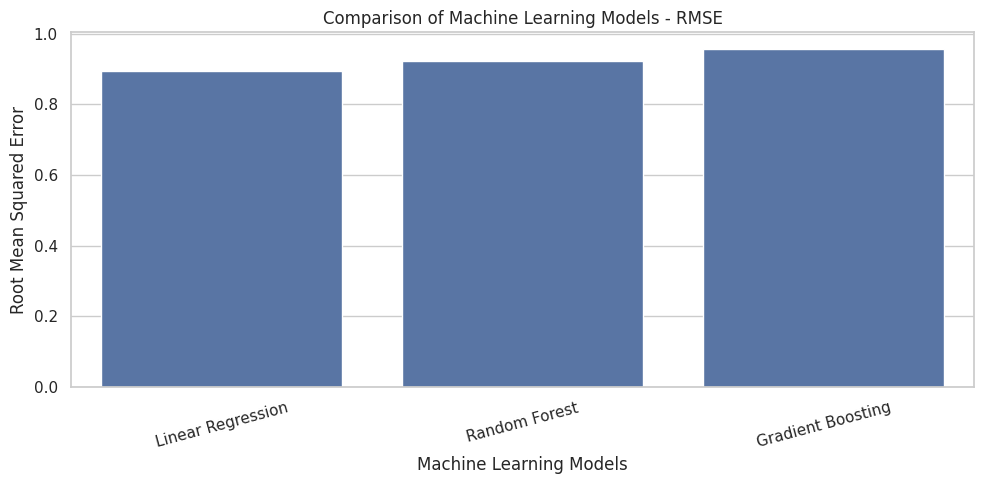

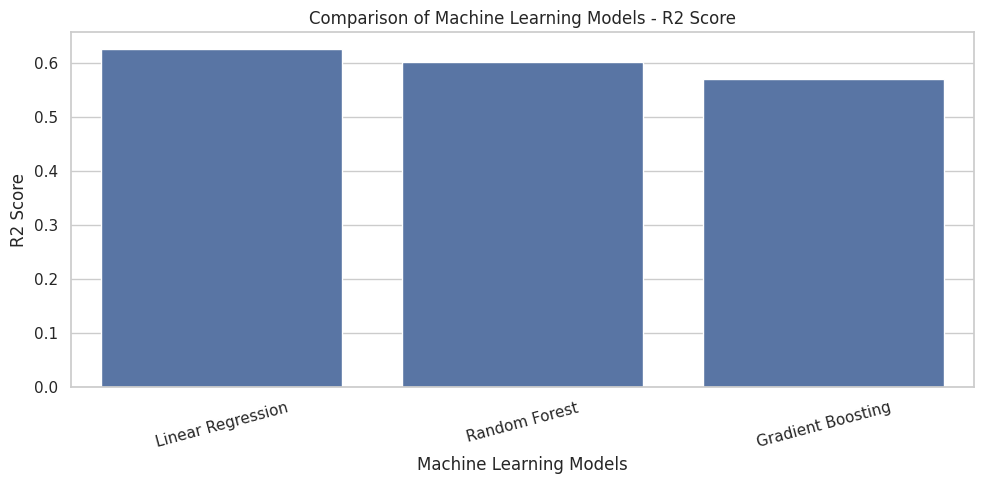

Model comparison charts saved successfully!


In [65]:
# STEP 51: MODEL PERFORMANCE VISUALIZATION

# Compare RMSE values
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Machine Learning Models - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("19_model_rmse_comparison.png", dpi=300)
plt.show()


# Compare R2 scores
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Machine Learning Models - R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("20_model_r2_comparison.png", dpi=300)
plt.show()

print("Model comparison charts saved successfully!")

In [66]:
# STEP 52: FAST CROSS-VALIDATION

from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Use 3-fold cross-validation to reduce execution time
group_cv = GroupKFold(n_splits=3)

# Restaurant groups
train_groups = groups.iloc[train_indices]

# Faster Random Forest model
fast_rf_model = RandomForestRegressor(
    n_estimators=30,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Cross-validation for Linear Regression
linear_cv_scores = cross_val_score(
    linear_model,
    X_train_reduced,
    y_train,
    cv=group_cv,
    groups=train_groups,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

# Cross-validation for Random Forest
rf_cv_scores = cross_val_score(
    fast_rf_model,
    X_train_final,
    y_train,
    cv=group_cv,
    groups=train_groups,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

# Cross-validation for Gradient Boosting
gb_cv_scores = cross_val_score(
    gradient_boosting_model,
    X_train_reduced,
    y_train,
    cv=group_cv,
    groups=train_groups,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

# Display results
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Mean CV RMSE": [
        -linear_cv_scores.mean(),
        -rf_cv_scores.mean(),
        -gb_cv_scores.mean()
    ],
    "Standard Deviation": [
        linear_cv_scores.std(),
        rf_cv_scores.std(),
        gb_cv_scores.std()
    ]
})

print("========== CROSS-VALIDATION RESULTS ==========")

display(cv_results.round(4))

print("\nCross-validation completed successfully!")

========== CROSS-VALIDATION RESULTS ==========


,Model,Mean CV RMSE,Standard Deviation
0,Linear Regression,0.8823,0.0257
1,Random Forest,1.0011,0.0325
2,Gradient Boosting,0.9579,0.0288



Cross-validation completed successfully!


In [74]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_gb_model = GradientBoostingRegressor(
    n_estimators=30,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

best_gb_model.fit(X_train_reduced, y_train)

predictions = best_gb_model.predict(X_test_reduced)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))
print("Model training completed!")

MAE: 0.8862306173641603
RMSE: 1.0880144185774263
R2 Score: 0.4456406277568773
Model training completed!


In [75]:
# STEP 54: EVALUATE THE TUNED MODEL

# Predict ratings using the tuned model
tuned_predictions = best_gb_model.predict(X_test_reduced)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_mse = mean_squared_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, tuned_predictions)

print("========== TUNED MODEL EVALUATION ==========")

print("MAE:", round(tuned_mae, 4))
print("MSE:", round(tuned_mse, 4))
print("RMSE:", round(tuned_rmse, 4))
print("R2 Score:", round(tuned_r2, 4))

print("\nTuned model evaluation completed successfully!")

========== TUNED MODEL EVALUATION ==========
MAE: 0.8862
MSE: 1.1838
RMSE: 1.088
R2 Score: 0.4456

Tuned model evaluation completed successfully!


In [76]:
# STEP 55: FINAL MODEL COMPARISON

final_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        gb_mae,
        tuned_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        gb_rmse,
        tuned_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2,
        tuned_r2
    ]
})

print("========== FINAL MODEL COMPARISON ==========")

display(final_results.round(4))

# Select the model with the lowest RMSE
best_model_name = final_results.loc[
    final_results["RMSE"].idxmin(), "Model"
]

print("\nBest Model based on RMSE:", best_model_name)

# Store the selected model
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "Tuned Gradient Boosting": best_gb_model
}

best_model = models[best_model_name]

print("\nBest model selected successfully!")

========== FINAL MODEL COMPARISON ==========


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.7055,0.8933,0.6263
1,Random Forest,0.6999,0.9221,0.6018
2,Gradient Boosting,0.7631,0.9564,0.5717
3,Tuned Gradient Boosting,0.8862,1.0880,0.4456



Best Model based on RMSE: Linear Regression

Best model selected successfully!


========== TOP 20 IMPORTANT FEATURES ==========


,Feature,Importance
2699,not,0.1922
4904,worst,0.1406
450,bad,0.0890
1648,good,0.0360
532,best,0.0291
3040,pathetic,0.0231
671,but,0.0217
2896,order,0.0167
2678,no,0.0163
5000,Cost,0.0147


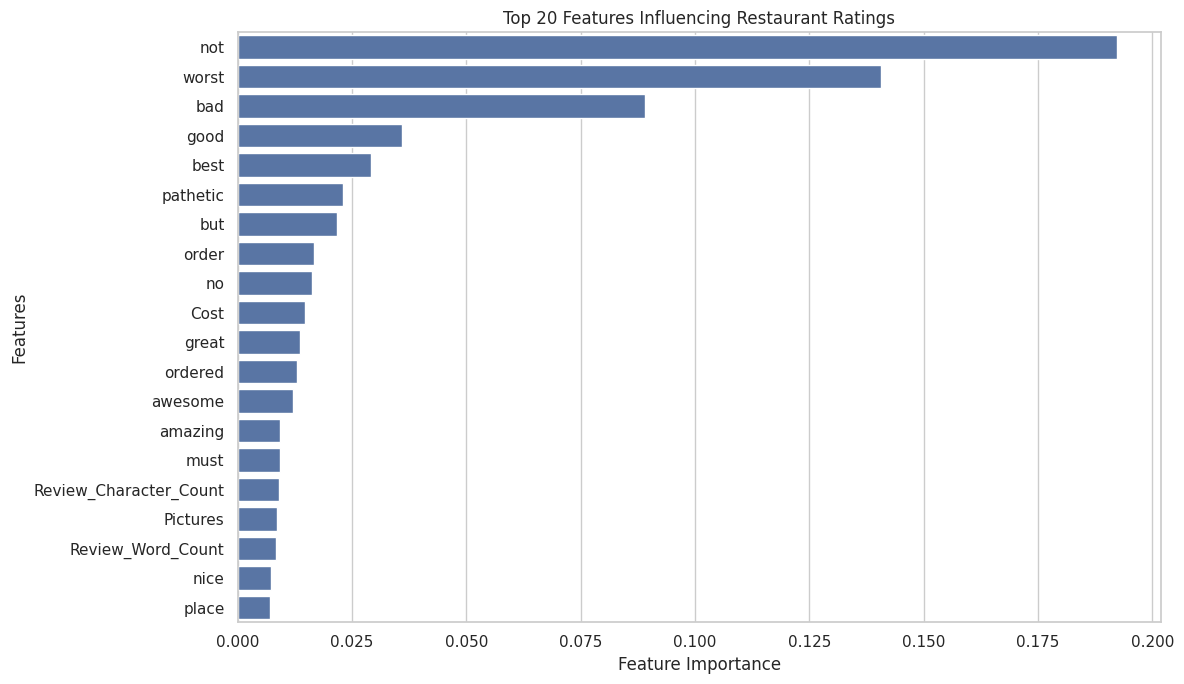


Feature importance analysis completed successfully!


In [77]:
# STEP 56: FEATURE IMPORTANCE

# Get feature names from TF-IDF
tfidf_features = tfidf.get_feature_names_out()

# Combine text and numerical feature names
all_feature_names = list(tfidf_features) + numerical_features

# Get feature importance
feature_importance = random_forest_model.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": feature_importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("========== TOP 20 IMPORTANT FEATURES ==========")

display(importance_df.head(20).round(4))

# Visualize top 20 features
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features Influencing Restaurant Ratings")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig("21_feature_importance.png", dpi=300)
plt.show()

print("\nFeature importance analysis completed successfully!")

========== ACTUAL VS PREDICTED RATINGS ==========


,Actual Rating,Predicted Rating
0,3.0,2.03
1,3.0,3.57
2,3.0,2.74
3,1.0,1.66
4,4.0,2.46
5,4.0,4.30
6,4.0,0.33
7,1.0,2.77
8,4.0,3.03
9,5.0,4.29


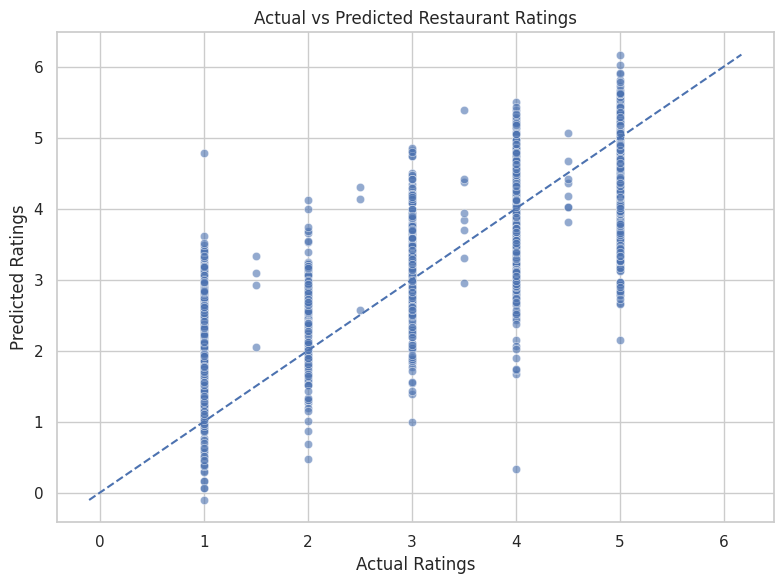


Actual vs Predicted analysis completed successfully!


In [78]:
# STEP 57: ACTUAL VS PREDICTED RATINGS

# Predict ratings using the selected best model
final_predictions = best_model.predict(
    X_test_reduced if best_model_name in [
        "Linear Regression",
        "Gradient Boosting",
        "Tuned Gradient Boosting"
    ] else X_test_final
)

# Create comparison DataFrame
prediction_df = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": final_predictions
})

print("========== ACTUAL VS PREDICTED RATINGS ==========")

display(prediction_df.head(15).round(2))

# Create scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=final_predictions,
    alpha=0.6
)

# Reference line
min_rating = min(y_test.min(), final_predictions.min())
max_rating = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_rating, max_rating],
    [min_rating, max_rating],
    linestyle="--"
)

plt.title("Actual vs Predicted Restaurant Ratings")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.tight_layout()

plt.savefig("22_actual_vs_predicted_ratings.png", dpi=300)
plt.show()

print("\nActual vs Predicted analysis completed successfully!")

In [80]:
# STEP 58: SAVE THE BEST MODEL

import joblib

# Save the selected model
joblib.dump(best_model, "zomato_best_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "zomato_tfidf_vectorizer.pkl")

# Save the scaler
joblib.dump(scaler, "zomato_scaler.pkl")

# Save the imputer
joblib.dump(numeric_imputer, "zomato_numeric_imputer.pkl")

# Save the SVD transformer
joblib.dump(svd, "zomato_svd_transformer.pkl")

print("========== MODEL SAVING REPORT ==========")

print("Selected Model:", best_model_name)
print("Best Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")
print("Scaler saved successfully!")
print("Imputer saved successfully!")
print("SVD transformer saved successfully!")

========== MODEL SAVING REPORT ==========
Selected Model: Linear Regression
Best Model saved successfully!
TF-IDF vectorizer saved successfully!
Scaler saved successfully!
Imputer saved successfully!
SVD transformer saved successfully!


In [81]:
# STEP 59: LOAD AND TEST THE SAVED MODEL

import joblib

# Load the saved model
loaded_model = joblib.load("zomato_best_model.pkl")

# Select the correct test data format
if best_model_name == "Random Forest":
    test_features = X_test_final
else:
    test_features = X_test_reduced

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(test_features)

# Display actual and predicted ratings
loaded_test_results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": loaded_predictions
})

print("========== LOADED MODEL TEST RESULTS ==========")

display(loaded_test_results.head(10).round(2))

# Calculate test performance
loaded_mae = mean_absolute_error(y_test, loaded_predictions)
loaded_rmse = np.sqrt(mean_squared_error(y_test, loaded_predictions))
loaded_r2 = r2_score(y_test, loaded_predictions)

print("\nLoaded Model:", best_model_name)
print("MAE:", round(loaded_mae, 4))
print("RMSE:", round(loaded_rmse, 4))
print("R2 Score:", round(loaded_r2, 4))

print("\nSaved model loaded and tested successfully!")

========== LOADED MODEL TEST RESULTS ==========


,Actual Rating,Predicted Rating
0,3.0,2.03
1,3.0,3.57
2,3.0,2.74
3,1.0,1.66
4,4.0,2.46
5,4.0,4.30
6,4.0,0.33
7,1.0,2.77
8,4.0,3.03
9,5.0,4.29



Loaded Model: Linear Regression
MAE: 0.7055
RMSE: 0.8933
R2 Score: 0.6263

Saved model loaded and tested successfully!


In [82]:
# STEP 60: FINAL PROJECT CONCLUSION

print("=" * 65)
print(" ZOMATO RESTAURANT REVIEW ANALYSIS AND RATING PREDICTION ")
print("=" * 65)

print("\nPROJECT SUMMARY")

print("""
This project focuses on analysing Zomato restaurant reviews
and predicting restaurant ratings using Machine Learning.

The project includes:
1. Data collection and understanding.
2. Data cleaning and preprocessing.
3. Exploratory Data Analysis (EDA).
4. Data visualization using different charts.
5. Hypothesis testing.
6. Feature engineering and selection.
7. Text preprocessing using TF-IDF.
8. Training three Machine Learning models.
9. Model evaluation and comparison.
10. Hyperparameter tuning.
11. Saving and testing the best model.
""")

print("\nBEST MODEL:", best_model_name)

print("\nMODEL PERFORMANCE")
print("MAE:", round(loaded_mae, 4))
print("RMSE:", round(loaded_rmse, 4))
print("R2 Score:", round(loaded_r2, 4))

print("""
\nBUSINESS IMPACT

The analysis can help restaurants understand customer
feedback, identify important review patterns, and improve
their services and customer satisfaction.

CONCLUSION

This project demonstrates how Machine Learning and
Natural Language Processing techniques can be used
to analyse restaurant reviews and predict customer ratings.
It also provides practical experience in data analysis,
visualization, preprocessing, and model evaluation.
""")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("=" * 65)

 ZOMATO RESTAURANT REVIEW ANALYSIS AND RATING PREDICTION 

PROJECT SUMMARY

This project focuses on analysing Zomato restaurant reviews
and predicting restaurant ratings using Machine Learning.

The project includes:
1. Data collection and understanding.
2. Data cleaning and preprocessing.
3. Exploratory Data Analysis (EDA).
4. Data visualization using different charts.
5. Hypothesis testing.
6. Feature engineering and selection.
7. Text preprocessing using TF-IDF.
8. Training three Machine Learning models.
9. Model evaluation and comparison.
10. Hyperparameter tuning.
11. Saving and testing the best model.


BEST MODEL: Linear Regression

MODEL PERFORMANCE
MAE: 0.7055
RMSE: 0.8933
R2 Score: 0.6263


BUSINESS IMPACT

The analysis can help restaurants understand customer
feedback, identify important review patterns, and improve
their services and customer satisfaction.

CONCLUSION

This project demonstrates how Machine Learning and
Natural Language Processing techniques can be used
to a

In [91]:
import os
import glob
import zipfile

output_folder = "/content/Zomato_Restaurant_ML_Project_Output"
os.makedirs(output_folder, exist_ok=True)

# Find project files
extensions = ["*.png", "*.pkl", "*.csv"]

for extension in extensions:
    for file in glob.glob("/content/" + extension):
        os.makedirs(output_folder, exist_ok=True)
        import shutil
        shutil.copy(file, output_folder)

# Create ZIP file
zip_path = "/content/Zomato_Restaurant_ML_Project_Output.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in glob.glob(output_folder + "/**/*", recursive=True):
        if os.path.isfile(file):
            zipf.write(
                file,
                os.path.relpath(file, "/content")
            )

print("ZIP file created successfully!")
print("Files included:", os.listdir(output_folder))

ZIP file created successfully!
Files included: ['zomato_best_model.pkl', '17_customer_sentiment_analysis.png', '06_cost_vs_rating.png', '05_average_rating_by_cuisine.png', 'zomato_numeric_imputer.pkl', '02_top_10_reviewed_restaurants.png', '13_top_10_restaurant_timings.png', '04_restaurant_cost_distribution.png', '08_rating_by_cost_category.png', '16_most_frequent_review_words.png', 'Zomato Restaurant names and Metadata.csv', '12_top_10_restaurant_collections.png', '22_actual_vs_predicted_ratings.png', 'zomato_scaler.pkl', '09_rating_by_review_hour.png', '14_ratings_by_picture_category.png', '19_model_rmse_comparison.png', '20_model_r2_comparison.png', '11_top_10_active_reviewers.png', '10_review_length_distribution.png', 'zomato_svd_transformer.pkl', 'Zomato Restaurant reviews.csv', '18_final_sentiment_vs_rating.png', '21_feature_importance.png', '15_numerical_features_correlation.png', '07_review_length_vs_rating.png', '03_top_10_popular_cuisines.png', 'zomato_tfidf_vectorizer.pkl']


In [93]:
from google.colab import files

files.download("Zomato_Restaurant_ML_Project_Output.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>